# Bali Tourism Data Integration & Analytics
**Sistem Akuisisi, Integrasi, dan Analisis Data Pariwisata Bali Menggunakan Open Dataset, API, dan Web Scraping**

UTS Data Acquisition & Management

| | |
|---|---|
| Nama | *(isi nama)* |
| NIM | *(isi NIM)* |
| Kelas / Dosen | *(isi)* |

**Cara memakai:** jalankan sel dari atas ke bawah (Runtime → Run all). Ganti `EMAIL_KAMPUS` pada sel konfigurasi dengan email kampus Anda sebelum menjalankan bagian API dan scraping. Saat diminta, unggah 5 file dataset (4 CSV + 1 Excel).

## BAGIAN 1 — Pendahuluan dan konfigurasi

**Latar belakang.** Pariwisata merupakan sektor utama Bali. Data pariwisata tersebar di banyak sumber dengan format berbeda (CSV dengan header bertingkat, Excel dengan sel gabungan dan rumus, API cuaca, dan halaman web). Projek ini membangun alur akuisisi, pembersihan, integrasi, validasi, dan dokumentasi (provenance) atas data tersebut.

**Tujuan.**
1. Mengidentifikasi dan membaca lima dataset terbuka (4 CSV + 1 Excel) dengan parameter sesuai struktur aslinya.
2. Mengambil data cuaca harian Bali dari API Open-Meteo.
3. Mengambil informasi destinasi wisata dari halaman web (web scraping) dengan mematuhi `robots.txt`.
4. Memeriksa lisensi dan etika data, membersihkan dan menormalisasi data.
5. Mengintegrasikan dua pasang sumber (Integrasi A: objek wisata + scraping, Integrasi B: pintu masuk + cuaca) dengan `merge(validate=...)`.
6. Memvalidasi hasil, membuat visualisasi eksploratif, dan mencatat provenance.

**Metode akuisisi.** Open dataset (file unggahan) · REST API (Open-Meteo Historical Weather) · Web scraping (`requests` + `BeautifulSoup`).

**Batasan.** Projek ini berfokus pada akuisisi dan integrasi data. Analisis bersifat eksploratif dan tidak membuktikan hubungan sebab-akibat.

In [1]:
# ===== 1.1 Import library =====
import os, sys, re, json, time, math, shutil, hashlib, difflib, unicodedata, calendar
import datetime as dt
from urllib import robotparser
from urllib.parse import urljoin, urlparse

import numpy as np
import pandas as pd
import requests
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

try:
    from IPython.display import display, Markdown
except Exception:          # cadangan jika dijalankan di luar Jupyter
    display = print
    Markdown = str

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print("pandas", pd.__version__, "| numpy", np.__version__, "| requests", requests.__version__)

pandas 2.2.3 | numpy 2.4.6 | requests 2.32.4


In [2]:
# ===== 1.2 Konfigurasi identitas, User-Agent, dan parameter request =====
EMAIL_KAMPUS = "mahasiswa@instiki.ac.id"     # <-- GANTI dengan email kampus Anda (jangan dibiarkan placeholder)
NAMA_MAHASISWA = "I Made Bagus Abiyoga Prawira"      # <-- GANTI
NIM = "2501010089"                     # <-- GANTI

# User-Agent memuat email kampus agar pengelola situs dapat menghubungi jika perlu
USER_AGENT = f"UTS-DataAcquisition-Bali/1.0 (+mailto:{EMAIL_KAMPUS}; keperluan akademik)"

REQUEST_TIMEOUT = 30      # detik, wajib pada setiap request
REQUEST_DELAY = 2         # detik jeda setelah setiap request
MAX_RETRY = 3             # jumlah percobaan ulang

if EMAIL_KAMPUS == "nama@kampus.ac.id":
    print("PERINGATAN: EMAIL_KAMPUS masih placeholder. Ganti sebelum dikumpulkan.")
print("User-Agent:", USER_AGENT)

User-Agent: UTS-DataAcquisition-Bali/1.0 (+mailto:mahasiswa@instiki.ac.id; keperluan akademik)


In [3]:
# ===== 1.3 Mount Google Drive dan membuat struktur folder =====
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/Bali_Tourism_Data_Project"
else:
    # Di luar Colab (uji lokal) folder dapat diatur lewat variabel lingkungan BALI_ROOT
    ROOT = os.environ.get("BALI_ROOT", os.path.abspath("Bali_Tourism_Data_Project"))

DIR_RAW = os.path.join(ROOT, "data", "raw")
DIR_PROC = os.path.join(ROOT, "data", "processed")
DIR_FINAL = os.path.join(ROOT, "data", "final")
DIR_META = os.path.join(ROOT, "metadata")
for d in (DIR_RAW, DIR_PROC, DIR_FINAL, DIR_META):
    os.makedirs(d, exist_ok=True)

FILE_PROVENANCE = os.path.join(ROOT, "provenance.csv")
FILE_ETIKA = os.path.join(ROOT, "data_ethics_checklist.csv")

# Penampung status setiap proses (dipakai pada bagian kesimpulan)
STATUS = {}
WAKTU_MULAI = dt.datetime.now()
print("Folder projek:", ROOT)
for d in (DIR_RAW, DIR_PROC, DIR_FINAL, DIR_META):
    print(" -", d)

Mounted at /content/drive
Folder projek: /content/drive/MyDrive/Bali_Tourism_Data_Project
 - /content/drive/MyDrive/Bali_Tourism_Data_Project/data/raw
 - /content/drive/MyDrive/Bali_Tourism_Data_Project/data/processed
 - /content/drive/MyDrive/Bali_Tourism_Data_Project/data/final
 - /content/drive/MyDrive/Bali_Tourism_Data_Project/metadata


In [4]:
# ===== 1.4 Fungsi bantu umum (dipakai di seluruh notebook) =====
def md5_file(path, blok=1024 * 1024):
    # Hitung hash MD5 sebuah file
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(blok), b""):
            h.update(b)
    return h.hexdigest()

def hari_ini():
    return dt.date.today().isoformat()

def http_get(url, params=None, tries=MAX_RETRY, tunggu=REQUEST_DELAY):
    # GET dengan timeout, User-Agent, jeda, dan retry (hanya untuk error sementara: 429/5xx/koneksi)
    for k in range(1, tries + 1):
        try:
            r = requests.get(url, params=params, timeout=REQUEST_TIMEOUT,
                             headers={"User-Agent": USER_AGENT, "Accept-Language": "id,en;q=0.8"})
            print(f"  [{k}/{tries}] GET {r.url[:110]} -> HTTP {r.status_code}")
            if r.status_code in (429, 500, 502, 503, 504):
                time.sleep(tunggu * k)          # backoff bertahap
                continue
            time.sleep(tunggu)                  # jeda sopan antar-request
            return r
        except requests.RequestException as e:
            print(f"  [{k}/{tries}] Error koneksi: {type(e).__name__}: {str(e)[:120]}")
            time.sleep(tunggu * k)
    return None

def ke_angka(x):
    # Ubah nilai teks/angka menjadi float. '-' dan sel kosong menjadi NaN (BUKAN nol).
    if x is None:
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return np.nan if (isinstance(x, float) and math.isnan(x)) else float(x)
    s = re.sub(r"\s+", "", str(x))               # hilangkan spasi pemisah ribuan
    if s in ("", "-", "–", "—"):
        return np.nan
    if re.fullmatch(r"-?\d+(\.\d+)?", s):
        return float(s)
    return np.nan

def bersihkan_teks(t):
    # Rapikan spasi berlebih
    return re.sub(r"\s+", " ", str(t) if t is not None else "").strip()

def kolom_teks(df):
    # Daftar kolom bertipe teks (kompatibel pandas 2 dan 3)
    return [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]

BULAN_ID = {"januari": 1, "februari": 2, "maret": 3, "april": 4, "mei": 5, "juni": 6, "juli": 7,
            "agustus": 8, "september": 9, "oktober": 10, "november": 11, "desember": 12}
NAMA_BULAN = {v: k.capitalize() for k, v in BULAN_ID.items()}

## BAGIAN 2 — Penyimpanan data RAW

Unggah kelima file. File asli **disalin tanpa modifikasi** ke `data/raw`; kecocokan salinan dibuktikan dengan hash MD5. Seluruh pengolahan berikutnya hanya menulis ke `data/processed` dan `data/final`.

In [5]:
# ===== 2.1 Unggah file dan salin ke data/raw =====
# Kata kunci (huruf kecil, spasi -> garis bawah) untuk mengenali tiap dataset dari nama file
KATA_KUNCI = {
    "D1_historis":   "bali_dan_indonesia",
    "D2_pintu":      "pintu_masuk",
    "D3_kebangsaan": "kebangsaan",
    "D4_menginap":   "lama_menginap",
    "D5_objek":      "table-17",
}

def kenali_dataset(nama_file):
    n = nama_file.lower().replace(" ", "_")
    for kunci, kw in KATA_KUNCI.items():
        if kw in n and n.endswith((".csv", ".xlsx")):
            return kunci
    return None

def cari_di_raw():
    # Cari file dataset yang sudah ada di data/raw
    hasil = {}
    for f in sorted(os.listdir(DIR_RAW)):
        k = kenali_dataset(f)
        if k:
            hasil[k] = os.path.join(DIR_RAW, f)
    return hasil

RAW_PATH = cari_di_raw()
kurang = [k for k in KATA_KUNCI if k not in RAW_PATH]

if kurang:
    if IN_COLAB:
        from google.colab import files
        print("Unggah file yang belum ada:", kurang)
        DIR_UPLOAD = "/content/upload_tmp"
        os.makedirs(DIR_UPLOAD, exist_ok=True)
        os.chdir(DIR_UPLOAD)
        files.upload()                      # dialog unggah muncul di sini
        os.chdir("/content")
    else:
        DIR_UPLOAD = os.environ.get("BALI_UPLOAD", os.path.join(ROOT, "upload"))
        print("Mode lokal: membaca file dari", DIR_UPLOAD)

    for f in sorted(os.listdir(DIR_UPLOAD)):
        k = kenali_dataset(f)
        if k is None or k not in kurang:
            continue
        src, dst = os.path.join(DIR_UPLOAD, f), os.path.join(DIR_RAW, f)
        shutil.copy2(src, dst)              # salin apa adanya (tanpa mengubah isi)
        assert md5_file(src) == md5_file(dst), f"Salinan {f} berbeda dari aslinya!"
        print("Disalin ke raw:", f)
    RAW_PATH = cari_di_raw()

kurang = [k for k in KATA_KUNCI if k not in RAW_PATH]
if kurang:
    raise FileNotFoundError(f"Dataset belum lengkap, belum ada: {kurang}. Unggah file yang sesuai lalu jalankan ulang sel ini.")
print("\nSeluruh 5 dataset tersedia di data/raw:")
for k, p in RAW_PATH.items():
    print(f" - {k:14s} {os.path.basename(p)}")

Unggah file yang belum ada: ['D1_historis', 'D2_pintu', 'D3_kebangsaan', 'D4_menginap', 'D5_objek']


Saving _Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv to _Banyaknya Wisatawan Mancanegara yang Datang Langsung ke Bali Menurut Kebangsaan 2019-2024.csv
Saving Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv to Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv
Saving Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2026.csv to Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2026.csv
Saving Rata-Rata Lama Menginap Tamu Asing dan Domestik pada Hotel Bintang Menurut Kelas dan Bulan di Provinsi Bali, 2026.csv to Rata-Rata Lama Menginap Tamu Asing dan Domestik pada Hotel Bintang Menurut Kelas dan Bulan di Provinsi Bali, 2026.csv
Saving Table-17-Final-7.xlsx to Table-17-Final-7.xlsx
Disalin ke raw: Banyaknya Wisatawan Mancanegara ke Bali dan Indonesia, 1969-2025.csv
Disalin ke raw: Jumlah Wisatawan Mancanegara Bulanan ke Bali Menurut Pintu Masuk, 2026.csv
Disalin ke raw: 

In [6]:
# ===== 2.2 Hash MD5 dan ukuran file =====
baris = []
for k, p in RAW_PATH.items():
    b = os.path.getsize(p)
    baris.append({"kode": k, "nama_file": os.path.basename(p), "ukuran_byte": b,
                  "ukuran_KB": round(b / 1024, 3), "ukuran_MB": round(b / 1024 ** 2, 6), "md5": md5_file(p)})
df_file = pd.DataFrame(baris)
display(df_file)
STATUS["Penyimpanan raw (5 dataset + MD5)"] = "berhasil"

,kode,nama_file,ukuran_byte,ukuran_KB,ukuran_MB,md5
0,D1_historis,Banyaknya Wisatawan Mancanegara ke Bali dan In...,3277,3.200,0.003125,ab034ea9e86e16ae85766ee2b37f2af3
1,D2_pintu,Jumlah Wisatawan Mancanegara Bulanan ke Bali M...,462,0.451,0.000441,2aef9e8b657603ba358b9d8bfb120410
2,D4_menginap,Rata-Rata Lama Menginap Tamu Asing dan Domesti...,654,0.639,0.000624,18a8dabfca1d1058afbf370999a97aa9
3,D5_objek,Table-17-Final-7.xlsx,63824,62.328,0.060867,ce9d625286e52fd80a8c58558a08e1e2
4,D3_kebangsaan,_Banyaknya Wisatawan Mancanegara yang Datang L...,2964,2.895,0.002827,de3d83169c1492b8b035c264e6a0a148


## BAGIAN 3 — Akuisisi dan identifikasi dataset

Struktur tiap file diperiksa dulu sebelum dibaca. Temuan dari pemeriksaan struktur:

| Dataset | Struktur khusus | Cara membaca |
|---|---|---|
| D1 Historis | Judul 2 baris, header 2 baris, **dua blok tahun berdampingan** (1969–1997 dan 1998–2025), angka dengan spasi ribuan (`86 067`), `-` | `header=None`, ambil blok kiri (kolom 0–4) dan kanan (kolom 6–10), gabungkan |
| D2 Pintu masuk | Judul, baris tahun, header bulan, kolom `Tahunan` kosong (`-`), bulan Okt–Des belum ada | Cari baris header bulan, ubah ke format *long* |
| D3 Kebangsaan | Header 2 bahasa, **baris benua (subtotal)** bercampur baris negara, spasi ribuan, `-` | Parsing per baris dengan penanda `level` (negara / subtotal_benua / total) |
| D4 Lama menginap | Judul, tahun, header bulan, `-` untuk bulan belum tersedia | Sama dengan D2 |
| D5 Excel | Judul 4 baris, **header tahun bertingkat**, kolom 2016–2017 **tidak** dipisah wisnus/wisman, baris kabupaten (I–IX), baris JUMLAH/TOTAL, **rumus** (`=800726+690129`), `-` | `openpyxl(data_only=True)`, petakan kolom ke (tahun, kategori), ubah ke *long* |

Nilai `-` diperlakukan sebagai **tidak tersedia (NaN)**, bukan nol. Angka `0` yang memang tertulis di sumber tetap `0`.

In [7]:
# ===== 3.1 Parser dataset 1: wisatawan mancanegara Bali & Indonesia 1969-2025 =====
def baca_raw_csv(path):
    # Baca CSV mentah apa adanya (semua teks) untuk pemeriksaan struktur
    return pd.read_csv(path, header=None, dtype=str, keep_default_na=False, skip_blank_lines=False)

def parse_historis(path):
    raw = baca_raw_csv(path)
    idx = raw.index[raw[0].str.strip() == "Tahun"][0]       # baris header 'Tahun'
    badan = raw.iloc[idx + 2:]                               # data mulai setelah 2 baris header
    kolom = ["tahun", "wisman_indonesia", "pertumbuhan_indonesia_pct", "wisman_bali", "pertumbuhan_bali_pct"]
    kiri = badan[[0, 1, 2, 3, 4]].set_axis(kolom, axis=1)    # blok 1969-1997
    kanan = badan[[6, 7, 8, 9, 10]].set_axis(kolom, axis=1)  # blok 1998-2025
    df = pd.concat([kiri, kanan], ignore_index=True)
    df = df[df["tahun"].str.strip().str.fullmatch(r"\d{4}")].copy()   # buang baris kosong/sumber
    df["tahun"] = df["tahun"].str.strip().astype(int)
    for c in kolom[1:]:
        df[c] = df[c].map(ke_angka)
    return df.sort_values("tahun").reset_index(drop=True), raw.shape

p_hist, shape_hist = parse_historis(RAW_PATH["D1_historis"])
print("Ukuran mentah:", shape_hist, "| observasi tahun valid:", len(p_hist))
display(p_hist.head())
display(p_hist.tail())

Ukuran mentah: (101, 11) | observasi tahun valid: 57


,tahun,wisman_indonesia,pertumbuhan_indonesia_pct,wisman_bali,pertumbuhan_bali_pct
0,1969,86067.0,NaN,11278.0,NaN
1,1970,129319.0,50.25,24340.0,115.82
2,1971,178781.0,38.25,34313.0,40.97
3,1972,221195.0,23.72,47004.0,36.99
4,1973,270303.0,22.20,53803.0,14.46


,tahun,wisman_indonesia,pertumbuhan_indonesia_pct,wisman_bali,pertumbuhan_bali_pct
52,2021,1557530.0,-61.57,51.0,NaN
53,2022,5889031.0,278.10,2155747.0,NaN
54,2023,11677825.0,98.30,5273258.0,144.61
55,2024,13902420.0,19.05,6333360.0,20.10
56,2025,15386646.0,10.80,6948754.0,9.72


In [8]:
# ===== 3.2 Parser dataset 2 & 4: tabel bulanan (pintu masuk; lama menginap) =====
def parse_bulanan(path, nama_label, nama_nilai):
    # Ubah tabel [baris kategori x bulan] menjadi format long: (label, tahun, bulan, nilai)
    raw = baca_raw_csv(path)
    r_hdr = [i for i in raw.index if raw.loc[i, 1].strip().lower() == "januari"][0]   # baris header bulan
    tahun = None
    for i in range(r_hdr):                                   # cari baris tahun di atas header
        for v in raw.loc[i]:
            if re.fullmatch(r"\d{4}", v.strip()):
                tahun = int(v.strip())
    kol_bulan = {c: BULAN_ID[raw.loc[r_hdr, c].strip().lower()] for c in raw.columns
                 if raw.loc[r_hdr, c].strip().lower() in BULAN_ID}
    kol_tahunan = [c for c in raw.columns if raw.loc[r_hdr, c].strip().lower() == "tahunan"]
    rows = []
    for i in range(r_hdr + 1, len(raw)):
        label = bersihkan_teks(raw.loc[i, 0])
        if not label:
            continue
        for c, m in kol_bulan.items():
            nilai = ke_angka(raw.loc[i, c])
            rows.append({nama_label: label, "tahun": tahun, "bulan_num": m, "bulan": NAMA_BULAN[m],
                         nama_nilai: nilai,
                         "status_data": "tersedia" if not np.isnan(nilai) else "belum_tersedia ('-' di sumber)"})
    tahunan_kosong = all(np.isnan(ke_angka(raw.loc[i, c])) for i in range(r_hdr + 1, len(raw))
                         if bersihkan_teks(raw.loc[i, 0]) for c in kol_tahunan)
    return pd.DataFrame(rows), raw.shape, tahunan_kosong

p_pintu, shape_pintu, tahunan_kosong_pintu = parse_bulanan(
    RAW_PATH["D2_pintu"], "pintu_masuk", "jumlah_wisman")
p_inap, shape_inap, tahunan_kosong_inap = parse_bulanan(
    RAW_PATH["D4_menginap"], "kelas_hotel", "rata_lama_menginap_malam")

print("D2 ukuran mentah:", shape_pintu, "| baris long:", len(p_pintu),
      "| terisi:", int(p_pintu.jumlah_wisman.notna().sum()), "| kolom 'Tahunan' kosong semua:", tahunan_kosong_pintu)
print("D4 ukuran mentah:", shape_inap, "| baris long:", len(p_inap),
      "| terisi:", int(p_inap.rata_lama_menginap_malam.notna().sum()), "| kolom 'Tahunan' kosong semua:", tahunan_kosong_inap)
display(p_pintu.head(4))
display(p_inap.head(4))

D2 ukuran mentah: (7, 14) | baris long: 36 | terisi: 27 | kolom 'Tahunan' kosong semua: True
D4 ukuran mentah: (10, 14) | baris long: 72 | terisi: 54 | kolom 'Tahunan' kosong semua: True


,pintu_masuk,tahun,bulan_num,bulan,jumlah_wisman,status_data
0,Bandara Ngurah Rai,2026,1,Januari,500121.0,tersedia
1,Bandara Ngurah Rai,2026,2,Februari,486053.0,tersedia
2,Bandara Ngurah Rai,2026,3,Maret,465260.0,tersedia
3,Bandara Ngurah Rai,2026,4,April,552961.0,tersedia


,kelas_hotel,tahun,bulan_num,bulan,rata_lama_menginap_malam,status_data
0,Bintang 5,2026,1,Januari,3.19,tersedia
1,Bintang 5,2026,2,Februari,2.83,tersedia
2,Bintang 5,2026,3,Maret,2.90,tersedia
3,Bintang 5,2026,4,April,3.13,tersedia


In [9]:
# ===== 3.3 Parser dataset 3: wisatawan menurut kebangsaan 2019-2024 =====
BENUA_MAP = {"I.": "ASEAN", "II.": "Asia (non-ASEAN)", "III.": "Amerika", "IV.": "Eropa",
             "V.": "Oseania", "VI.": "Afrika", "VII.": "Crew"}

def parse_kebangsaan(path):
    raw = baca_raw_csv(path)
    r_hdr = raw.index[raw[0].str.strip().str.startswith("Kebangsaan")][0]
    kol_tahun = {c: int(raw.loc[r_hdr, c].strip()) for c in raw.columns
                 if re.fullmatch(r"\d{4}", raw.loc[r_hdr, c].strip())}
    benua, rows = None, []
    for i in range(r_hdr + 2, len(raw)):
        c0, c1, c2 = (bersihkan_teks(raw.loc[i, k]) for k in (0, 1, 2))
        if c1.lower().startswith("pertumbuhan") or c0.lower().startswith("sumber"):
            continue                                          # baris pertumbuhan & catatan sumber
        if c1.lower().startswith("jumlah"):
            level, benua_i, negara_raw = "total", "Total", "Jumlah / Total"
        elif re.fullmatch(r"[IVX]+\.", c0):
            benua = BENUA_MAP[c0]
            level, benua_i, negara_raw = "subtotal_benua", benua, c1
        elif c2:
            level, benua_i, negara_raw = "negara", benua, c2
        else:
            continue
        bagian = [b.strip() for b in negara_raw.split(" / ")]
        for c, th in kol_tahun.items():
            rows.append({"benua": benua_i, "level": level, "negara_raw": negara_raw,
                         "negara_id": bagian[0], "negara_en": bagian[-1], "tahun": th,
                         "jumlah_wisman": ke_angka(raw.loc[i, c])})
    df = pd.DataFrame(rows)
    df["status_data"] = np.where(df["jumlah_wisman"].notna(), "tersedia", "tidak_tersedia ('-' di sumber)")
    return df, raw.shape

p_negara, shape_negara = parse_kebangsaan(RAW_PATH["D3_kebangsaan"])
print("D3 ukuran mentah:", shape_negara, "| baris long:", len(p_negara))
print(p_negara.level.value_counts().to_dict())
display(p_negara[p_negara.level == "negara"].head(6))

D3 ukuran mentah: (41, 12) | baris long: 198
{'negara': 150, 'subtotal_benua': 42, 'total': 6}


,benua,level,negara_raw,negara_id,negara_en,tahun,jumlah_wisman,status_data
6,ASEAN,negara,Malaysia / Malaysia,Malaysia,Malaysia,2019,185256.0,tersedia
7,ASEAN,negara,Malaysia / Malaysia,Malaysia,Malaysia,2020,31587.0,tersedia
8,ASEAN,negara,Malaysia / Malaysia,Malaysia,Malaysia,2021,NaN,tidak_tersedia ('-' di sumber)
9,ASEAN,negara,Malaysia / Malaysia,Malaysia,Malaysia,2022,91064.0,tersedia
10,ASEAN,negara,Malaysia / Malaysia,Malaysia,Malaysia,2023,207573.0,tersedia
11,ASEAN,negara,Malaysia / Malaysia,Malaysia,Malaysia,2024,246145.0,tersedia


In [10]:
# ===== 3.4 Parser dataset 5: Excel Table 17 (objek & daya tarik wisata) =====
KAB_MAP = {"DENPASAR CITY": "Denpasar", "BADUNG REGENCY": "Badung", "GIANYAR REGENCY": "Gianyar",
           "BANGLI REGENCY": "Bangli", "KLUNGKUNG REGENCY": "Klungkung", "KARANGASEM REGENCY": "Karangasem",
           "BULELENG REGENCY": "Buleleng", "JEMBRANA REGENCY": "Jembrana", "KABUPATEN TABANAN": "Tabanan"}

def parse_excel_objek(path):
    wb_v = openpyxl.load_workbook(path, data_only=True)        # nilai hasil hitung rumus (cache Excel)
    wb_f = openpyxl.load_workbook(path, data_only=False)       # rumus asli, untuk memeriksa cache
    ws, wf = wb_v.worksheets[0], wb_f.worksheets[0]

    # Rumus yang tidak punya nilai cache akan terbaca None -> beri peringatan
    tanpa_cache = sum(1 for row in wf.iter_rows() for c in row
                      if isinstance(c.value, str) and c.value.startswith("=") and ws[c.coordinate].value is None)
    if tanpa_cache:
        print(f"PERINGATAN: {tanpa_cache} sel rumus tidak punya nilai cache. Buka file di Excel/LibreOffice, simpan ulang, lalu unggah lagi.")

    # --- cari baris header tahun dan sub-header wisnus/wisman ---
    r_th = next(r for r in range(1, 20) if "VISITED" in str(ws.cell(r, 2).value).upper())
    r_sb = next(r for r in range(r_th + 1, r_th + 6)
                if any(str(ws.cell(r, c).value).strip().lower() in ("wisnus", "wisman") for c in range(3, ws.max_column + 1)))

    # --- petakan tiap kolom ke (tahun, kategori) ---
    # Kolom 2016 & 2017 hanya satu angka per tahun (tidak dipisah) -> kategori 'total_gabungan'
    kolom_map, tahun_aktif = {}, None
    for c in range(3, ws.max_column + 1):
        th, sb = ws.cell(r_th, c).value, ws.cell(r_sb, c).value
        if th is not None:
            tahun_aktif = int(str(th).strip())
        sb = str(sb).strip().lower() if sb is not None else None
        if th is None and sb is None:
            continue                                            # kolom tanpa header (kolom kosong di ujung)
        kolom_map[c] = (tahun_aktif, sb if sb in ("wisnus", "wisman") else "total_gabungan")

    # --- baca baris: kabupaten (romawi), objek (nomor), JUMLAH/TOTAL ---
    kab, rows, jumlah_sumber, abaikan = None, [], [], []
    for r in range(r_sb + 1, ws.max_row + 1):
        a, b = ws.cell(r, 1).value, bersihkan_teks(ws.cell(r, 2).value)
        if isinstance(a, str) and re.fullmatch(r"[IVX]+", a.strip()) and b:
            kab = KAB_MAP.get(b.upper(), b.title())
            continue
        if b.upper() in ("JUMLAH", "TOTAL") or (a is None and not b and ws.cell(r, 3).value is not None):
            for c, (th, kt) in kolom_map.items():                # simpan subtotal sumber utk validasi silang
                jumlah_sumber.append({"kabupaten": "TOTAL" if b.upper() == "TOTAL" else kab,
                                      "tahun": th, "kategori": kt, "nilai_sumber": ke_angka(ws.cell(r, c).value)})
            continue
        if isinstance(a, (int, float)) and b:
            for c, (th, kt) in kolom_map.items():
                v = ws.cell(r, c).value
                if v is None:
                    status, nilai = "kosong_di_sumber", np.nan
                elif isinstance(v, str) and v.strip() == "-":
                    status, nilai = "tidak_tersedia ('-' di sumber)", np.nan
                else:
                    nilai = ke_angka(v)
                    status = "tersedia" if not np.isnan(nilai) else "tidak_terbaca"
                rows.append({"no": int(a), "objek": b, "kabupaten": kab, "tahun": th,
                             "kategori": kt, "kunjungan": nilai, "status_data": status})
        elif b or a is not None:
            abaikan.append((r, a, b))
    df = pd.DataFrame(rows)
    return df, pd.DataFrame(jumlah_sumber), (ws.max_row, ws.max_column), kolom_map, abaikan

p_objek, jumlah_sumber, shape_objek, kolom_map, baris_diabaikan = parse_excel_objek(RAW_PATH["D5_objek"])
print("D5 ukuran mentah (baris x kolom):", shape_objek)
print("Pemetaan kolom -> (tahun, kategori):", {openpyxl.utils.get_column_letter(c): v for c, v in kolom_map.items()})
print("Jumlah objek wisata unik (kabupaten+nama):", p_objek[["kabupaten", "objek"]].drop_duplicates().shape[0])
print("Baris long (objek x tahun x kategori):", len(p_objek))
print("Observasi dengan nilai valid:", int(p_objek.kunjungan.notna().sum()))
print(p_objek.status_data.value_counts().to_dict())
if baris_diabaikan:
    print("Baris non-data yang dilewati:", baris_diabaikan[:10])
display(p_objek.head(6))

D5 ukuran mentah (baris x kolom): (322, 22)
Pemetaan kolom -> (tahun, kategori): {'C': (2016, 'total_gabungan'), 'D': (2017, 'total_gabungan'), 'E': (2018, 'wisnus'), 'F': (2018, 'wisman'), 'G': (2019, 'wisnus'), 'H': (2019, 'wisman'), 'I': (2020, 'wisnus'), 'J': (2020, 'wisman'), 'K': (2021, 'wisnus'), 'L': (2021, 'wisman'), 'M': (2022, 'wisnus'), 'N': (2022, 'wisman'), 'O': (2023, 'wisnus'), 'P': (2023, 'wisman'), 'Q': (2024, 'wisnus'), 'R': (2024, 'wisman'), 'S': (2025, 'wisnus'), 'T': (2025, 'wisman')}
Jumlah objek wisata unik (kabupaten+nama): 290
Baris long (objek x tahun x kategori): 5220
Observasi dengan nilai valid: 3531
{'tersedia': 3531, "tidak_tersedia ('-' di sumber)": 1651, 'kosong_di_sumber': 38}
Baris non-data yang dilewati: [(321, None, 'BALI GOVERNMENT TOURISM OFFICE'), (322, None, 'DINAS PARIWISATA PROVINSI BALI')]


,no,objek,kabupaten,tahun,kategori,kunjungan,status_data
0,1,Museum Bali,Denpasar,2016,total_gabungan,38437.0,tersedia
1,1,Museum Bali,Denpasar,2017,total_gabungan,31693.0,tersedia
2,1,Museum Bali,Denpasar,2018,wisnus,18927.0,tersedia
3,1,Museum Bali,Denpasar,2018,wisman,16704.0,tersedia
4,1,Museum Bali,Denpasar,2019,wisnus,18815.0,tersedia
5,1,Museum Bali,Denpasar,2019,wisman,13457.0,tersedia


In [11]:
# ===== 3.5 Tabel identifikasi kelima dataset =====
def periode(s):
    s = pd.Series(s).dropna()
    return f"{int(s.min())}-{int(s.max())}"

ident = pd.DataFrame([
    {"dataset": "D1 Wisman Bali & Indonesia", "file": os.path.basename(RAW_PATH["D1_historis"]), "jenis_file": "CSV", "jenis_data": "Deret waktu tahunan (historis)",
     "baris_mentah": shape_hist[0], "kolom_mentah": shape_hist[1], "observasi_valid": len(p_hist), "kolom_bersih": ", ".join(p_hist.columns),
     "satuan": "orang (wisatawan); pertumbuhan dalam %", "cakupan_wilayah": "Indonesia & Provinsi Bali", "cakupan_waktu": periode(p_hist.tahun),
     "missing_nilai": int(p_hist.drop(columns="tahun").isna().sum().sum())},
    {"dataset": "D2 Wisman bulanan per pintu masuk", "file": os.path.basename(RAW_PATH["D2_pintu"]), "jenis_file": "CSV", "jenis_data": "Data bulanan (kategori x bulan)",
     "baris_mentah": shape_pintu[0], "kolom_mentah": shape_pintu[1], "observasi_valid": int(p_pintu.jumlah_wisman.notna().sum()), "kolom_bersih": ", ".join(p_pintu.columns),
     "satuan": "kunjungan (orang)", "cakupan_wilayah": "Provinsi Bali (pintu masuk)", "cakupan_waktu": f"{p_pintu.tahun.iloc[0]} (bulan terisi: {p_pintu.dropna(subset=['jumlah_wisman']).bulan_num.min()}-{p_pintu.dropna(subset=['jumlah_wisman']).bulan_num.max()})",
     "missing_nilai": int(p_pintu.jumlah_wisman.isna().sum())},
    {"dataset": "D3 Wisman menurut kebangsaan", "file": os.path.basename(RAW_PATH["D3_kebangsaan"]), "jenis_file": "CSV", "jenis_data": "Tabulasi negara asal x tahun (ada subtotal)",
     "baris_mentah": shape_negara[0], "kolom_mentah": shape_negara[1], "observasi_valid": int(p_negara.jumlah_wisman.notna().sum()), "kolom_bersih": ", ".join(p_negara.columns),
     "satuan": "orang (datang langsung)", "cakupan_wilayah": "Bali (negara asal wisman)", "cakupan_waktu": periode(p_negara.tahun),
     "missing_nilai": int(p_negara.jumlah_wisman.isna().sum())},
    {"dataset": "D4 Lama menginap hotel bintang", "file": os.path.basename(RAW_PATH["D4_menginap"]), "jenis_file": "CSV", "jenis_data": "Data bulanan (kelas hotel x bulan)",
     "baris_mentah": shape_inap[0], "kolom_mentah": shape_inap[1], "observasi_valid": int(p_inap.rata_lama_menginap_malam.notna().sum()), "kolom_bersih": ", ".join(p_inap.columns),
     "satuan": "malam (rata-rata)", "cakupan_wilayah": "Provinsi Bali (hotel bintang)", "cakupan_waktu": f"{p_inap.tahun.iloc[0]} (bulan terisi: {p_inap.dropna(subset=['rata_lama_menginap_malam']).bulan_num.min()}-{p_inap.dropna(subset=['rata_lama_menginap_malam']).bulan_num.max()})",
     "missing_nilai": int(p_inap.rata_lama_menginap_malam.isna().sum())},
    {"dataset": "D5 Objek & daya tarik wisata", "file": os.path.basename(RAW_PATH["D5_objek"]), "jenis_file": "Excel (sheet 'Table 17')", "jenis_data": "Panel objek wisata x tahun x kategori",
     "baris_mentah": shape_objek[0], "kolom_mentah": shape_objek[1], "observasi_valid": int(p_objek.kunjungan.notna().sum()), "kolom_bersih": ", ".join(p_objek.columns),
     "satuan": "kunjungan (orang)", "cakupan_wilayah": "9 kabupaten/kota di Bali", "cakupan_waktu": periode(p_objek.tahun),
     "missing_nilai": int(p_objek.kunjungan.isna().sum())},
])
ident = ident.merge(df_file[["nama_file", "ukuran_KB"]].rename(columns={"nama_file": "file"}), on="file", how="left")
display(ident.drop(columns=["kolom_bersih"]))

# Tipe data setiap dataset
for nm, d in [("D1", p_hist), ("D2", p_pintu), ("D3", p_negara), ("D4", p_inap), ("D5", p_objek)]:
    print(f"\nTipe data {nm}:", d.dtypes.astype(str).to_dict())

# Bukti syarat jumlah baris
print("\nSyarat >=100 observasi valid pada dataset utama (D5):", int(p_objek.kunjungan.notna().sum()),
      "->", "TERPENUHI" if p_objek.kunjungan.notna().sum() >= 100 else "BELUM TERPENUHI")
print("Jumlah objek wisata unik:", p_objek[['kabupaten','objek']].drop_duplicates().shape[0])
ident.to_csv(os.path.join(DIR_META, "identifikasi_dataset.csv"), index=False)
STATUS["Identifikasi 5 dataset"] = "berhasil"

,dataset,file,jenis_file,jenis_data,baris_mentah,kolom_mentah,observasi_valid,satuan,cakupan_wilayah,cakupan_waktu,missing_nilai,ukuran_KB
0,D1 Wisman Bali & Indonesia,Banyaknya Wisatawan Mancanegara ke Bali dan In...,CSV,Deret waktu tahunan (historis),101,11,57,orang (wisatawan); pertumbuhan dalam %,Indonesia & Provinsi Bali,1969-2025,4,3.200
1,D2 Wisman bulanan per pintu masuk,Jumlah Wisatawan Mancanegara Bulanan ke Bali M...,CSV,Data bulanan (kategori x bulan),7,14,27,kunjungan (orang),Provinsi Bali (pintu masuk),2026 (bulan terisi: 1-9),9,0.451
2,D3 Wisman menurut kebangsaan,_Banyaknya Wisatawan Mancanegara yang Datang L...,CSV,Tabulasi negara asal x tahun (ada subtotal),41,12,160,orang (datang langsung),Bali (negara asal wisman),2019-2024,38,2.895
3,D4 Lama menginap hotel bintang,Rata-Rata Lama Menginap Tamu Asing dan Domesti...,CSV,Data bulanan (kelas hotel x bulan),10,14,54,malam (rata-rata),Provinsi Bali (hotel bintang),2026 (bulan terisi: 1-9),18,0.639
4,D5 Objek & daya tarik wisata,Table-17-Final-7.xlsx,Excel (sheet 'Table 17'),Panel objek wisata x tahun x kategori,322,22,3531,kunjungan (orang),9 kabupaten/kota di Bali,2016-2025,1689,62.328



Tipe data D1: {'tahun': 'int64', 'wisman_indonesia': 'float64', 'pertumbuhan_indonesia_pct': 'float64', 'wisman_bali': 'float64', 'pertumbuhan_bali_pct': 'float64'}

Tipe data D2: {'pintu_masuk': 'object', 'tahun': 'int64', 'bulan_num': 'int64', 'bulan': 'object', 'jumlah_wisman': 'float64', 'status_data': 'object'}

Tipe data D3: {'benua': 'object', 'level': 'object', 'negara_raw': 'object', 'negara_id': 'object', 'negara_en': 'object', 'tahun': 'int64', 'jumlah_wisman': 'float64', 'status_data': 'object'}

Tipe data D4: {'kelas_hotel': 'object', 'tahun': 'int64', 'bulan_num': 'int64', 'bulan': 'object', 'rata_lama_menginap_malam': 'float64', 'status_data': 'object'}

Tipe data D5: {'no': 'int64', 'objek': 'object', 'kabupaten': 'object', 'tahun': 'int64', 'kategori': 'object', 'kunjungan': 'float64', 'status_data': 'object'}

Syarat >=100 observasi valid pada dataset utama (D5): 3531 -> TERPENUHI
Jumlah objek wisata unik: 290


In [12]:
# ===== 3.6 Catatan kualitas struktur yang ditemukan saat identifikasi =====
catatan = []

# (a) Kolom 2016-2017 di Excel tidak dipisah wisnus/wisman
kat = p_objek.groupby("tahun").kategori.unique().map(list)
catatan.append(f"D5: kategori per tahun -> {kat.to_dict()}. Tahun 2016-2017 hanya 'total_gabungan' (diasumsikan jumlah wisnus+wisman; VERIFIKASI dengan sumber).")

# (b) Dataset 4 memuat satu angka per kelas-bulan (tidak dipisah asing/domestik)
catatan.append("D4: satu nilai rata-rata per kelas hotel per bulan; file TIDAK memisahkan tamu asing dan domestik, sehingga perbandingan asing vs domestik tidak dapat dibuat dari file ini.")

# (c) Nilai tidak tersedia
catatan.append(f"D2/D4: bulan Oktober-Desember bertanda '-' => NaN. D3: tahun 2021 seluruh negara '-' (hanya total=51 di sumber).")

# (d) Nilai ekstrem D1
h = p_hist.set_index("tahun")
catatan.append(f"D1: wisman Bali 2021 = {int(h.loc[2021,'wisman_bali'])} (sangat rendah dibanding 2020 = {int(h.loc[2020,'wisman_bali'])}); dipertahankan sesuai sumber, perlu disebut sebagai nilai anomali.")

# (e) Duplikasi nama objek pada D5
dup_nama = p_objek[["kabupaten", "objek"]].drop_duplicates().objek.str.lower().duplicated().sum()
catatan.append(f"D5: nama objek yang muncul lebih dari sekali (di kabupaten berbeda/ditulis ganda): {dup_nama}.")

for c in catatan:
    print("-", c)

- D5: kategori per tahun -> {2016: ['total_gabungan'], 2017: ['total_gabungan'], 2018: ['wisnus', 'wisman'], 2019: ['wisnus', 'wisman'], 2020: ['wisnus', 'wisman'], 2021: ['wisnus', 'wisman'], 2022: ['wisnus', 'wisman'], 2023: ['wisnus', 'wisman'], 2024: ['wisnus', 'wisman'], 2025: ['wisnus', 'wisman']}. Tahun 2016-2017 hanya 'total_gabungan' (diasumsikan jumlah wisnus+wisman; VERIFIKASI dengan sumber).
- D4: satu nilai rata-rata per kelas hotel per bulan; file TIDAK memisahkan tamu asing dan domestik, sehingga perbandingan asing vs domestik tidak dapat dibuat dari file ini.
- D2/D4: bulan Oktober-Desember bertanda '-' => NaN. D3: tahun 2021 seluruh negara '-' (hanya total=51 di sumber).
- D1: wisman Bali 2021 = 51 (sangat rendah dibanding 2020 = 1069473); dipertahankan sesuai sumber, perlu disebut sebagai nilai anomali.
- D5: nama objek yang muncul lebih dari sekali (di kabupaten berbeda/ditulis ganda): 1.


## BAGIAN 4 — Estimasi kebutuhan storage

Rumus: **Storage = (Ukuran file × 12) × 1,3**

Asumsi: setiap bulan diambil satu berkas dengan ukuran sama dengan berkas awal (12 pengambilan per tahun), ditambah cadangan 30% untuk versi olahan, cadangan, dan pertumbuhan data.

In [13]:
# ===== 4.1 Hitung estimasi storage =====
FAKTOR_BULAN, FAKTOR_CADANGAN = 12, 1.3
est = df_file[["kode", "nama_file", "ukuran_byte"]].copy()
est["ukuran_KB"] = est.ukuran_byte / 1024
est["bulanan_KB"] = est.ukuran_KB                                  # asumsi: ukuran file bulanan = ukuran file awal
est["tahunan_KB"] = est.bulanan_KB * FAKTOR_BULAN                  # 12 pengambilan
est["cadangan_30pct_KB"] = est.tahunan_KB * (FAKTOR_CADANGAN - 1)  # tambahan 30%
est["total_KB"] = est.tahunan_KB * FAKTOR_CADANGAN                 # (ukuran x 12) x 1.3
est["total_MB"] = est.total_KB / 1024

total = est[["ukuran_KB", "bulanan_KB", "tahunan_KB", "cadangan_30pct_KB", "total_KB", "total_MB"]].sum()
tampil = est.drop(columns=["ukuran_byte"]).round(3)
tampil.loc[len(tampil)] = ["TOTAL", "-", *total.round(3).tolist()]
display(tampil)
print(f"Total kebutuhan storage 1 tahun untuk 5 dataset: {total['total_KB']:.2f} KB = {total['total_MB']:.4f} MB")
print("Catatan: belum termasuk respons API, HTML hasil scraping, dan file olahan (lihat bagian 12 untuk ukuran aktual).")
est.round(4).to_csv(os.path.join(DIR_META, "estimasi_storage.csv"), index=False)
STATUS["Estimasi storage"] = "berhasil"

,kode,nama_file,ukuran_KB,bulanan_KB,tahunan_KB,cadangan_30pct_KB,total_KB,total_MB
0,D1_historis,Banyaknya Wisatawan Mancanegara ke Bali dan In...,3.200,3.200,38.402,11.521,49.923,0.049
1,D2_pintu,Jumlah Wisatawan Mancanegara Bulanan ke Bali M...,0.451,0.451,5.414,1.624,7.038,0.007
2,D4_menginap,Rata-Rata Lama Menginap Tamu Asing dan Domesti...,0.639,0.639,7.664,2.299,9.963,0.010
3,D5_objek,Table-17-Final-7.xlsx,62.328,62.328,747.938,224.381,972.319,0.950
4,D3_kebangsaan,_Banyaknya Wisatawan Mancanegara yang Datang L...,2.895,2.895,34.734,10.420,45.155,0.044
5,TOTAL,-,69.513,69.513,834.152,250.246,1084.398,1.059


Total kebutuhan storage 1 tahun untuk 5 dataset: 1084.40 KB = 1.0590 MB
Catatan: belum termasuk respons API, HTML hasil scraping, dan file olahan (lihat bagian 12 untuk ukuran aktual).


## BAGIAN 5 — Lisensi dan Data Ethics Checklist (9 butir)

Pemeriksaan otomatis dilakukan terhadap PII dan quasi-identifier. **Lisensi tidak dikarang:** isi kamus `LISENSI` dan `URL_SUMBER` di bawah setelah memeriksa portal asli. Selama belum diisi, statusnya "Belum terverifikasi". Hasil akhir checklist diperbarui lagi di Bagian 12 setelah API dan scraping selesai.

In [14]:
# ===== 5.1 Informasi sumber & lisensi (ISI MANUAL setelah verifikasi portal) =====
BELUM = "Belum terverifikasi"
URL_SUMBER = {
    "D1_historis": BELUM, "D2_pintu": BELUM, "D3_kebangsaan": BELUM, "D4_menginap": BELUM, "D5_objek": BELUM,
    "API_openmeteo": "https://archive-api.open-meteo.com/v1/archive",
    "SCRAPING": "https://www.indonesia.travel/id/id/destination/bali-nusa-tenggara/bali",
}
LISENSI = {
    "D1_historis": BELUM, "D2_pintu": BELUM, "D3_kebangsaan": BELUM, "D4_menginap": BELUM, "D5_objek": BELUM,
    "API_openmeteo": BELUM + " (periksa https://open-meteo.com/en/license)",
    "SCRAPING": BELUM + " (periksa syarat & ketentuan situs)",
}
# Penerbit sesuai keterangan yang tercantum di dalam file (bukan klaim lisensi)
PENERBIT = {
    "D1_historis": "BPS Provinsi Bali (tercantum pada baris 'Sumber/Source' di file)",
    "D2_pintu": "Belum terverifikasi (file tidak mencantumkan sumber; kemungkinan BPS Provinsi Bali)",
    "D3_kebangsaan": "BPS Provinsi Bali (tercantum pada baris 'Sumber/Source' di file)",
    "D4_menginap": "Belum terverifikasi (file tidak mencantumkan sumber; kemungkinan BPS Provinsi Bali)",
    "D5_objek": "Dinas Pariwisata Provinsi Bali (tercantum di bagian bawah sheet; BUKAN otomatis BPS)",
    "API_openmeteo": "Open-Meteo.com",
    "SCRAPING": "Kementerian Pariwisata RI / Indonesia.Travel (verifikasi)",
}

In [15]:
# ===== 5.2 Pemindaian PII dan quasi-identifier =====
POLA_PII = {"email": r"[\w\.\-]+@[\w\.\-]+\.\w{2,}", "telepon": r"(?:\+62|\b0)8\d{8,11}\b", "nik_16_digit": r"\b\d{16}\b"}
KATA_KOLOM_PII = ["email", "telepon", "phone", "alamat", "nik", "ktp", "paspor", "passport", "nama_lengkap", "tanggal_lahir"]

def scan_pii(nama, df):
    # Cek nama kolom dan isi sel teks terhadap pola PII
    temuan = []
    for c in df.columns:
        if any(k in c.lower() for k in KATA_KOLOM_PII):
            temuan.append(f"kolom '{c}' bernama mirip PII")
    for c in kolom_teks(df):
        s = df[c].dropna().astype(str)
        for jenis, pola in POLA_PII.items():
            n = int(s.str.contains(pola, regex=True).sum())
            if n:
                temuan.append(f"{n} sel di kolom '{c}' cocok pola {jenis}")
    return temuan

hasil_pii = {nm: scan_pii(nm, d) for nm, d in
             [("D1", p_hist), ("D2", p_pintu), ("D3", p_negara), ("D4", p_inap), ("D5", p_objek)]}
for k, v in hasil_pii.items():
    print(k, "->", v if v else "tidak ditemukan PII (kolom & isi sel teks)")

# Quasi-identifier: data berupa agregat; periksa sel terkecil (risiko re-identifikasi pada kelompok kecil)
sel_terkecil = {
    "D3 (negara x tahun)": p_negara[(p_negara.level == "negara")].jumlah_wisman.replace(0, np.nan).min(),
    "D5 (objek x tahun x kategori)": p_objek.kunjungan.replace(0, np.nan).min(),
}
print("\nNilai agregat positif terkecil:", sel_terkecil)

D1 -> tidak ditemukan PII (kolom & isi sel teks)
D2 -> tidak ditemukan PII (kolom & isi sel teks)
D3 -> tidak ditemukan PII (kolom & isi sel teks)
D4 -> tidak ditemukan PII (kolom & isi sel teks)
D5 -> tidak ditemukan PII (kolom & isi sel teks)

Nilai agregat positif terkecil: {'D3 (negara x tahun)': 321.0, 'D5 (objek x tahun x kategori)': 1.0}


In [16]:
# ===== 5.3 Menyusun checklist 9 butir =====
def bangun_etika(state=None):
    s = state or {}
    pii_ok = all(len(v) == 0 for v in hasil_pii.values())
    lisensi_belum = [k for k, v in LISENSI.items() if v.startswith(BELUM)]
    nama_min = int(min(v for v in sel_terkecil.values() if pd.notna(v)))
    rows = [
        (1, "Legalitas dan lisensi", "Belum terverifikasi" if lisensi_belum else "Terpenuhi",
         "Kamus LISENSI di notebook; penerbit tercantum di file: " + "; ".join(f"{k}: {v}" for k, v in PENERBIT.items() if k.startswith("D")),
         f"Lisensi belum terverifikasi untuk: {', '.join(lisensi_belum) if lisensi_belum else '-'}. Isi setelah memeriksa portal sumber; tidak ditebak."),
        (2, "Tujuan pengumpulan data", "Terpenuhi",
         "Bagian 1 notebook (Tujuan projek)", "Data dipakai untuk tugas akademik (UTS) akuisisi & integrasi data pariwisata; bukan untuk komersial atau profiling individu."),
        (3, "Privasi dan PII", "Terpenuhi" if pii_ok else "Perlu ditinjau",
         "Pemindaian kolom & isi sel (email, telepon, NIK 16 digit, nama kolom mirip PII): " + json.dumps({k: len(v) for k, v in hasil_pii.items()}),
         "Seluruh dataset berupa agregat statistik (jumlah wisatawan, nama objek wisata, nama negara, cuaca). Tidak ada data pribadi individu."),
        (4, "Quasi-identifier", "Terpenuhi (risiko rendah)",
         f"Nilai agregat positif terkecil = {nama_min} (orang). Atribut: wilayah, tahun, bulan, kebangsaan, objek wisata.",
         "Kombinasi atribut hanya mengidentifikasi kelompok (bukan individu). Sel dengan nilai sangat kecil tetap agregat sehingga risiko re-identifikasi rendah."),
        (5, "Persetujuan dan hak penggunaan", s.get("etika5_status", "Belum terverifikasi"),
         s.get("etika5_bukti", "Ketentuan portal belum diperiksa; robots.txt akan diperiksa di Bagian 7"),
         s.get("etika5_jelas", "Pastikan syarat penggunaan portal BPS/Dinas Pariwisata/Open-Meteo/Indonesia.Travel mengizinkan penggunaan akademik dan beri atribusi.")),
        (6, "Transparansi sumber", s.get("etika6_status", "Sebagian"),
         s.get("etika6_bukti", "provenance.csv (dibuat di Bagian 12)"),
         s.get("etika6_jelas", "URL sumber dataset belum diisi (kamus URL_SUMBER) sehingga transparansi baru sebagian.")),
        (7, "Keamanan data", "Terpenuhi",
         "Tidak ada API key/token pada notebook (Open-Meteo tanpa key); penyimpanan di Google Drive pribadi; data mentah tidak diubah (MD5 dicatat).",
         "Jangan menaruh kredensial pada notebook. Jangan membagikan folder Drive secara publik kecuali dibutuhkan untuk pengumpulan."),
        (8, "Potensi bias", "Terpenuhi (diidentifikasi)",
         s.get("etika8_bukti", "Cakupan: D2/D4 hanya 2026 (Jan-Sep), D3 2019-2024 (2021 kosong), D5 2016-2025 (2016-2017 tidak dipisah), cuaca satu titik (Denpasar)."),
         "Cuaca satu titik Denpasar tidak mewakili seluruh Bali; data pandemi (2020-2021) berpengaruh besar; nilai '-' dibiarkan NaN sehingga total bisa under-count."),
        (9, "Risiko penyalahgunaan", "Terpenuhi (diidentifikasi)",
         "Evaluasi penggunaan hasil analisis (Bagian 11-13)",
         "Hasil bersifat eksploratif; korelasi cuaca-kunjungan tidak boleh ditafsirkan sebagai sebab-akibat; tidak untuk keputusan kebijakan tanpa validasi tambahan."),
    ]
    return pd.DataFrame(rows, columns=["no", "aspek_etika", "status", "bukti", "penjelasan"])

df_etika = bangun_etika()
display(df_etika)
df_etika.to_csv(FILE_ETIKA, index=False)
STATUS["Data ethics checklist (awal)"] = "berhasil"

,no,aspek_etika,status,bukti,penjelasan
0,1,Legalitas dan lisensi,Belum terverifikasi,Kamus LISENSI di notebook; penerbit tercantum ...,Lisensi belum terverifikasi untuk: D1_historis...
1,2,Tujuan pengumpulan data,Terpenuhi,Bagian 1 notebook (Tujuan projek),Data dipakai untuk tugas akademik (UTS) akuisi...
2,3,Privasi dan PII,Terpenuhi,"Pemindaian kolom & isi sel (email, telepon, NI...",Seluruh dataset berupa agregat statistik (juml...
3,4,Quasi-identifier,Terpenuhi (risiko rendah),Nilai agregat positif terkecil = 1 (orang). At...,Kombinasi atribut hanya mengidentifikasi kelom...
4,5,Persetujuan dan hak penggunaan,Belum terverifikasi,Ketentuan portal belum diperiksa; robots.txt a...,Pastikan syarat penggunaan portal BPS/Dinas Pa...
5,6,Transparansi sumber,Sebagian,provenance.csv (dibuat di Bagian 12),URL sumber dataset belum diisi (kamus URL_SUMB...
6,7,Keamanan data,Terpenuhi,Tidak ada API key/token pada notebook (Open-Me...,Jangan menaruh kredensial pada notebook. Janga...
7,8,Potensi bias,Terpenuhi (diidentifikasi),"Cakupan: D2/D4 hanya 2026 (Jan-Sep), D3 2019-2...",Cuaca satu titik Denpasar tidak mewakili selur...
8,9,Risiko penyalahgunaan,Terpenuhi (diidentifikasi),Evaluasi penggunaan hasil analisis (Bagian 11-13),Hasil bersifat eksploratif; korelasi cuaca-kun...


## BAGIAN 6 — Akuisisi data API Open-Meteo

Endpoint: `https://archive-api.open-meteo.com/v1/archive` (Historical Weather API, tanpa API key). Lokasi: Denpasar (-8.65, 115.2167). Periode: 1 Januari 2026 sampai tanggal terakhir yang tersedia (data arsip biasanya tertinggal beberapa hari, sehingga `end_date` diset hari ini − 5).

In [17]:
# ===== 6.1 Ambil data cuaca harian dari Open-Meteo =====
API_URL = "https://archive-api.open-meteo.com/v1/archive"
LAT, LON = -8.6500, 115.2167
VAR_HARIAN = ["temperature_2m_max", "temperature_2m_min", "precipitation_sum", "rain_sum", "wind_speed_10m_max", "weather_code"]
TGL_MULAI = "2026-01-01"
TGL_AKHIR = (dt.date.today() - dt.timedelta(days=5)).isoformat()   # data arsip tertunda beberapa hari
FILE_API_RAW = os.path.join(DIR_RAW, "open_meteo_raw.json")
FILE_WEATHER_DAILY = os.path.join(DIR_PROC, "weather_daily.csv")

def ambil_cuaca(mulai, akhir):
    params = {"latitude": LAT, "longitude": LON, "start_date": mulai, "end_date": akhir,
              "daily": ",".join(VAR_HARIAN), "timezone": "Asia/Makassar"}   # WITA (zona waktu Bali)
    try:
        r = http_get(API_URL, params=params)
        if r is None:
            return None, "Tidak ada respons (jaringan/ timeout). Periksa koneksi lalu jalankan ulang."
        if r.status_code != 200:
            return None, f"HTTP {r.status_code}: {r.text[:200]}"
        js = r.json()
        if "daily" not in js:
            return None, f"Respons tidak memuat kunci 'daily': {str(js)[:200]}"
        return (js, params), None
    except Exception as e:                                           # tangkap error tak terduga (mis. JSON rusak)
        return None, f"{type(e).__name__}: {e}"

hasil_api, galat_api = ambil_cuaca(TGL_MULAI, TGL_AKHIR)
if galat_api:
    print("GAGAL mengambil data API ->", galat_api)
    print("Cara memperbaiki: pastikan runtime Colab terhubung internet, tunggu beberapa menit (batas laju), lalu jalankan ulang sel ini.")
    weather_daily = pd.DataFrame(columns=["date"] + VAR_HARIAN)
    STATUS["API Open-Meteo"] = f"GAGAL: {galat_api}"
else:
    js, params_pakai = hasil_api
    with open(FILE_API_RAW, "w", encoding="utf-8") as f:           # simpan respons MENTAH apa adanya
        json.dump(js, f, ensure_ascii=False, indent=1)
    d = pd.DataFrame(js["daily"]).rename(columns={"time": "date"})  # normalisasi JSON -> DataFrame
    d["date"] = pd.to_datetime(d["date"])
    weather_daily = d
    weather_daily.to_csv(FILE_WEATHER_DAILY, index=False)
    print("Satuan dari API:", js.get("daily_units"))
    print("Koordinat grid yang dipakai API:", js.get("latitude"), js.get("longitude"), "| elevasi:", js.get("elevation"))
    STATUS["API Open-Meteo"] = "berhasil"

print("\nJumlah baris:", len(weather_daily), "| syarat >=30 baris:", "TERPENUHI" if len(weather_daily) >= 30 else "BELUM TERPENUHI")
if len(weather_daily):
    assert len(weather_daily) >= 30, "Data API kurang dari 30 baris"
    print("Rentang tanggal:", weather_daily.date.min().date(), "s.d.", weather_daily.date.max().date())
    print("\nMissing values:"); print(weather_daily.isna().sum())
    display(weather_daily.head()); display(weather_daily.describe().T)

  [1/3] GET https://archive-api.open-meteo.com/v1/archive?latitude=-8.65&longitude=115.2167&start_date=2026-01-01&end_date -> HTTP 200
Satuan dari API: {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'rain_sum': 'mm', 'wind_speed_10m_max': 'km/h', 'weather_code': 'wmo code'}
Koordinat grid yang dipakai API: -8.681898 115.193794 | elevasi: 35.0

Jumlah baris: 316 | syarat >=30 baris: TERPENUHI
Rentang tanggal: 2026-01-01 s.d. 2026-11-12

Missing values:
date                  0
temperature_2m_max    0
temperature_2m_min    0
precipitation_sum     0
rain_sum              0
wind_speed_10m_max    0
weather_code          0
dtype: int64


,date,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,wind_speed_10m_max,weather_code
0,2026-01-01,32.7,24.8,0.6,0.6,9.9,51
1,2026-01-02,31.3,25.3,2.8,2.8,12.9,53
2,2026-01-03,31.5,24.6,0.6,0.6,10.4,51
3,2026-01-04,32.4,23.1,3.4,3.4,16.3,61
4,2026-01-05,28.7,24.1,9.9,9.9,19.8,63


,count,mean,min,25%,50%,75%,max,std
date,316,2026-06-07 12:00:00,2026-01-01 00:00:00,2026-03-20 18:00:00,2026-06-07 12:00:00,2026-08-25 06:00:00,2026-11-12 00:00:00,NaN
temperature_2m_max,316.0,29.350949,24.8,28.5,29.5,30.1,33.2,1.223616
temperature_2m_min,316.0,23.208228,19.5,22.4,23.5,24.125,25.8,1.303814
precipitation_sum,316.0,4.807595,0.0,0.3,1.5,4.9,82.4,9.430966
rain_sum,316.0,4.807595,0.0,0.3,1.5,4.9,82.4,9.430966
wind_speed_10m_max,316.0,17.963608,7.8,15.7,18.45,20.8,32.8,4.181111
weather_code,316.0,47.056962,1.0,51.0,51.0,61.0,65.0,19.678283


In [18]:
# ===== 6.2 Agregasi cuaca harian -> bulanan =====
WMO = {0: "Cerah", 1: "Cerah berawan", 2: "Berawan sebagian", 3: "Mendung", 45: "Kabut", 48: "Kabut es", 51: "Gerimis ringan",
       53: "Gerimis sedang", 55: "Gerimis lebat", 61: "Hujan ringan", 63: "Hujan sedang", 65: "Hujan lebat", 80: "Hujan lokal ringan",
       81: "Hujan lokal sedang", 82: "Hujan lokal lebat", 95: "Badai petir", 96: "Badai petir + es", 99: "Badai petir + es lebat"}

KOLOM_BULANAN = ["tahun", "bulan_num", "suhu_max_rata2", "suhu_min_rata2", "curah_hujan_total_mm", "hujan_total_mm",
                 "angin_max_rata2", "hari_hujan", "hari_valid", "hari_dalam_bulan", "bulan_lengkap"]

def agregasi_bulanan(wd):
    if wd.empty:
        return pd.DataFrame(columns=KOLOM_BULANAN)
    w = wd.copy()
    w["tahun"], w["bulan_num"] = w.date.dt.year, w.date.dt.month
    g = w.groupby(["tahun", "bulan_num"]).agg(
        suhu_max_rata2=("temperature_2m_max", "mean"), suhu_min_rata2=("temperature_2m_min", "mean"),
        curah_hujan_total_mm=("precipitation_sum", lambda s: s.sum(min_count=1)),
        hujan_total_mm=("rain_sum", lambda s: s.sum(min_count=1)),
        angin_max_rata2=("wind_speed_10m_max", "mean"),
        hari_hujan=("precipitation_sum", lambda s: int((s >= 1).sum())),     # hari hujan: >= 1 mm
        hari_valid=("precipitation_sum", "count")).reset_index()
    g["hari_dalam_bulan"] = [calendar.monthrange(int(y), int(m))[1] for y, m in zip(g.tahun, g.bulan_num)]
    g["bulan_lengkap"] = g.hari_valid == g.hari_dalam_bulan                  # False = bulan belum penuh (sedang berjalan)
    return g

weather_monthly = agregasi_bulanan(weather_daily)
if len(weather_daily):
    weather_daily["kondisi_cuaca"] = weather_daily["weather_code"].map(WMO).fillna("Kode lain")
    weather_daily.to_csv(FILE_WEATHER_DAILY, index=False)
weather_monthly.to_csv(os.path.join(DIR_PROC, "weather_monthly.csv"), index=False)
display(weather_monthly.round(2))

,tahun,bulan_num,suhu_max_rata2,suhu_min_rata2,curah_hujan_total_mm,hujan_total_mm,angin_max_rata2,hari_hujan,hari_valid,hari_dalam_bulan,bulan_lengkap
0,2026,1,29.55,24.23,297.8,297.8,18.24,27,31,31,True
1,2026,2,28.38,23.84,498.6,498.6,19.45,28,28,28,True
2,2026,3,29.39,24.18,169.3,169.3,17.29,25,31,31,True
3,2026,4,29.92,24.05,229.1,229.1,14.00,20,30,30,True
4,2026,5,29.64,23.92,81.7,81.7,17.14,24,31,31,True
5,2026,6,29.46,22.94,47.4,47.4,18.55,12,30,30,True
6,2026,7,28.20,21.34,34.4,34.4,20.08,13,31,31,True
7,2026,8,28.82,21.41,10.4,10.4,19.54,2,31,31,True
8,2026,9,29.23,22.39,23.3,23.3,19.78,9,30,30,True
9,2026,10,30.22,23.48,85.5,85.5,17.57,19,31,31,True


## BAGIAN 7 — Web scraping destinasi wisata Bali

Sumber: halaman destinasi Bali di Indonesia.Travel. Urutan proses: (1) ambil dan periksa `robots.txt` → (2) jika diizinkan, ambil HTML → (3) simpan HTML mentah → (4) ekstraksi dengan BeautifulSoup → (5) normalisasi menjadi tabel.

Aturan: tidak memakai Booking.com, Agoda, Traveloka, Tiket.com, Airbnb, Tripadvisor, Google Maps, atau media sosial. Data destinasi **tidak boleh dibuat manual** untuk menggantikan hasil scraping. Jika tidak diizinkan atau gagal, proses dihentikan dengan aman.

In [19]:
# ===== 7.1 Periksa robots.txt =====
URL_TARGET = URL_SUMBER["SCRAPING"]
FILE_ROBOTS = os.path.join(DIR_RAW, "robots_indonesia_travel.txt")

def cek_robots(url_target):
    p = urlparse(url_target)
    robots_url = f"{p.scheme}://{p.netloc}/robots.txt"
    r = http_get(robots_url)
    if r is None:
        return {"boleh": False, "status": None, "robots_url": robots_url, "teks": "",
                "alasan": "robots.txt tidak dapat diambil (jaringan/timeout) -> scraping dihentikan demi kehati-hatian"}
    if r.status_code == 404:
        return {"boleh": True, "status": 404, "robots_url": robots_url, "teks": "",
                "alasan": "robots.txt tidak ditemukan (404): tidak ada larangan eksplisit. Syarat & ketentuan situs tetap harus dipatuhi."}
    if r.status_code != 200:
        return {"boleh": False, "status": r.status_code, "robots_url": robots_url, "teks": r.text[:500],
                "alasan": f"robots.txt merespons HTTP {r.status_code} -> status izin tidak jelas, scraping dihentikan"}
    rp = robotparser.RobotFileParser()
    rp.parse(r.text.splitlines())
    boleh = rp.can_fetch(USER_AGENT, url_target)
    return {"boleh": boleh, "status": 200, "robots_url": robots_url, "teks": r.text, "parser": rp,
            "alasan": "robots.txt mengizinkan URL target untuk User-Agent kita" if boleh else "robots.txt MELARANG URL target -> scraping tidak dilakukan"}

robots = cek_robots(URL_TARGET)
print("URL target :", URL_TARGET)
print("robots.txt :", robots["robots_url"], "| status:", robots["status"])
print("Diizinkan  :", robots["boleh"])
print("Alasan     :", robots["alasan"])
if robots["teks"]:
    with open(FILE_ROBOTS, "w", encoding="utf-8") as f:
        f.write(robots["teks"])
    print("\nCuplikan robots.txt:\n" + "\n".join(robots["teks"].splitlines()[:25]))

  [1/3] GET https://www.indonesia.travel/robots.txt -> HTTP 200
URL target : https://www.indonesia.travel/id/id/destination/bali-nusa-tenggara/bali
robots.txt : https://www.indonesia.travel/robots.txt | status: 200
Diizinkan  : True
Alasan     : robots.txt mengizinkan URL target untuk User-Agent kita

Cuplikan robots.txt:
User-agent: *

Sitemap: https://indonesia.travel/sitemap.xml


In [20]:
# ===== 7.2 Ambil HTML (hanya jika robots.txt mengizinkan) dan ekstraksi =====
FILE_HTML_RAW = os.path.join(DIR_RAW, "tourism_scraping_raw.html")
FILE_DETAIL_RAW = os.path.join(DIR_RAW, "tourism_scraping_detail_raw.json")
FILE_SCRAPED = os.path.join(DIR_PROC, "destinasi_scraped.csv")
KOLOM_SCRAPED = ["nama_destinasi", "kategori", "kategori_metode", "deskripsi", "lokasi", "url_halaman", "metode_ekstraksi", "tanggal_akses"]

AMBIL_HALAMAN_DETAIL = True      # ambil halaman detail tiap destinasi (tiap URL dicek robots.txt & diberi jeda)
MAKS_DETAIL = 15                 # batasi jumlah request agar sopan
POLA_LINK_DETAIL = r"/(destination|destinasi|attraction|atraksi)/"   # ubah jika struktur URL situs berbeda

ATURAN_KATEGORI = [   # kategori diturunkan dari kata kunci (transparan, bukan dari situs); urutan = prioritas
    ("Budaya", ["pura", "desa adat", "candi", "museum", "puri", "istana", "tari", "upacara", "budaya", "tradisional"]),
    ("Alam", ["pantai", "air terjun", "gunung", "danau", "hutan", "terasering", "sawah", "bukit", "pulau", "kebun", "taman nasional", "tebing", "snorkel", "selam"]),
    ("Buatan", ["taman hiburan", "waterpark", "kebun binatang", "mal", "pasar seni", "spa"]),
]
def infer_kategori(teks):
    t = (teks or "").lower()
    for kat, kata in ATURAN_KATEGORI:
        if any(k in t for k in kata):
            return kat, "inferensi_kata_kunci"
    return "Belum terklasifikasi", "tidak_ada_kata_kunci"

def meta_halaman(soup):
    # Ambil judul & deskripsi dari tag og:/meta/h1 (biasanya tersedia pada HTML statis)
    og = lambda p: (soup.find("meta", property=p) or soup.find("meta", attrs={"name": p}) or {}).get("content")
    judul = og("og:title") or (soup.find("h1").get_text() if soup.find("h1") else None) or (soup.title.get_text() if soup.title else None)
    desk = og("og:description") or og("description")
    return bersihkan_teks(judul), bersihkan_teks(desk)

def ekstrak_dari_anchor(soup, base_url):
    # Strategi A: tautan menuju halaman destinasi/atraksi yang lebih dalam dari halaman target
    path_target = urlparse(base_url).path.rstrip("/").lower()
    hasil = {}
    for a in soup.find_all("a", href=True):
        href = urljoin(base_url, a["href"]).split("#")[0]
        path = urlparse(href).path.lower().rstrip("/")
        if not re.search(POLA_LINK_DETAIL, path + "/") or path == path_target:
            continue
        if not (path.startswith(path_target + "/") or re.search(r"/(attraction|atraksi)/", path)):
            continue
        h = a.find(["h1", "h2", "h3", "h4", "h5"])
        nama = bersihkan_teks(h.get_text() if h else a.get_text())
        if not (3 <= len(nama) <= 90):
            continue
        p = a.find("p") or (a.parent.find("p") if a.parent else None)
        lok = None
        wadah = a.parent if a.parent else a
        el = wadah.find(attrs={"class": re.compile(r"(location|lokasi|region|city)", re.I)})
        if el:
            lok = bersihkan_teks(el.get_text())
        hasil.setdefault(href, {"nama_destinasi": nama, "deskripsi": bersihkan_teks(p.get_text()) if p else None,
                                "lokasi": lok, "url_halaman": href, "metode_ekstraksi": "anchor_link"})
    return list(hasil.values())

def ekstrak_dari_heading(soup, base_url):
    # Strategi B (cadangan): heading h2-h4 beserta paragraf sesudahnya
    hasil = []
    for h in soup.find_all(["h2", "h3", "h4"]):
        nama = bersihkan_teks(h.get_text())
        if not (3 <= len(nama) <= 90):
            continue
        p = h.find_next("p")
        hasil.append({"nama_destinasi": nama, "deskripsi": bersihkan_teks(p.get_text()) if p else None,
                      "lokasi": None, "url_halaman": base_url, "metode_ekstraksi": "heading_paragraf"})
    return hasil

def ekstrak_dari_jsonld(soup, base_url):
    # Strategi C (cadangan): data terstruktur JSON-LD (jika tersedia)
    hasil = []
    for s in soup.find_all("script", type="application/ld+json"):
        try:
            data = json.loads(s.string or "")
        except Exception:
            continue
        for item in (data if isinstance(data, list) else [data]):
            if isinstance(item, dict) and item.get("@type") in ("TouristAttraction", "Place", "TouristDestination") and item.get("name"):
                hasil.append({"nama_destinasi": bersihkan_teks(item["name"]), "deskripsi": bersihkan_teks(item.get("description")),
                              "lokasi": None, "url_halaman": item.get("url", base_url), "metode_ekstraksi": "json_ld"})
    return hasil

df_scraped = pd.DataFrame(columns=KOLOM_SCRAPED)
detail_html = {}

if not robots["boleh"]:
    print("SCRAPING DIHENTIKAN:", robots["alasan"])
    print("Alternatif: pilih sumber statis lain pada domain resmi (mis. situs dinas pariwisata/pemerintah daerah) yang robots.txt-nya mengizinkan, "
          "ubah URL_SUMBER['SCRAPING'], lalu jalankan ulang Bagian 7.")
    STATUS["Web scraping"] = "DIHENTIKAN: " + robots["alasan"]
else:
    r = http_get(URL_TARGET)
    if r is None or r.status_code != 200:
        print("GAGAL mengambil HTML:", "tidak ada respons" if r is None else f"HTTP {r.status_code}")
        STATUS["Web scraping"] = "GAGAL mengambil HTML"
    else:
        with open(FILE_HTML_RAW, "w", encoding="utf-8") as f:          # simpan HTML MENTAH
            f.write(r.text)
        soup = BeautifulSoup(r.text, "html.parser")
        kandidat = []
        for fungsi in (ekstrak_dari_anchor, ekstrak_dari_jsonld, ekstrak_dari_heading):   # urutan strategi
            kandidat = fungsi(soup, URL_TARGET)
            print(f"Strategi {fungsi.__name__}: {len(kandidat)} kandidat")
            if len(kandidat) >= 3:
                break

        # Perkaya dari halaman detail (hanya URL yang diizinkan robots.txt)
        if AMBIL_HALAMAN_DETAIL and kandidat and robots.get("parser"):
            for k in [x for x in kandidat if x["metode_ekstraksi"] == "anchor_link"][:MAKS_DETAIL]:
                if not robots["parser"].can_fetch(USER_AGENT, k["url_halaman"]):
                    print("  dilewati (dilarang robots):", k["url_halaman"]); continue
                rd = http_get(k["url_halaman"])
                if rd is not None and rd.status_code == 200:
                    detail_html[k["url_halaman"]] = rd.text
                    j, d = meta_halaman(BeautifulSoup(rd.text, "html.parser"))
                    if d and not k.get("deskripsi"):
                        k["deskripsi"] = d
        if detail_html:
            with open(FILE_DETAIL_RAW, "w", encoding="utf-8") as f:
                json.dump(detail_html, f, ensure_ascii=False)

        if kandidat:
            df_scraped = pd.DataFrame(kandidat)
            df_scraped["tanggal_akses"] = hari_ini()
            kk = df_scraped.apply(lambda x: infer_kategori(f"{x['nama_destinasi']} {x.get('deskripsi') or ''}"), axis=1)
            df_scraped["kategori"] = [k[0] for k in kk]
            df_scraped["kategori_metode"] = [k[1] for k in kk]
            df_scraped = df_scraped.reindex(columns=KOLOM_SCRAPED).drop_duplicates(subset=["nama_destinasi"]).reset_index(drop=True)
            df_scraped.to_csv(FILE_SCRAPED, index=False)
            STATUS["Web scraping"] = f"berhasil ({len(df_scraped)} destinasi)"
        else:
            print("Tidak ada destinasi yang berhasil diekstraksi dari HTML statis.")
            print("Kemungkinan halaman dirender JavaScript atau struktur HTML berubah. HTML mentah tetap tersimpan di", FILE_HTML_RAW)
            print("Perbaikan: periksa HTML mentah, sesuaikan POLA_LINK_DETAIL/fungsi ekstraksi, atau pakai halaman statis lain yang diizinkan robots.txt.")
            STATUS["Web scraping"] = "HTML diambil, tetapi 0 destinasi terekstrak"

print("\nJumlah destinasi hasil scraping:", len(df_scraped))
display(df_scraped.head(10))

  [1/3] GET https://www.indonesia.travel/id/id/destination/bali-nusa-tenggara/bali -> HTTP 200
Strategi ekstrak_dari_anchor: 0 kandidat
Strategi ekstrak_dari_jsonld: 0 kandidat
Strategi ekstrak_dari_heading: 33 kandidat

Jumlah destinasi hasil scraping: 33


,nama_destinasi,kategori,kategori_metode,deskripsi,lokasi,url_halaman,metode_ekstraksi,tanggal_akses
0,Informasi,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
1,Berita Terbaru Indonesia,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
2,Informasi Umum,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
3,Buku & Brosur Elektronik,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
4,Peraturan Bali,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
5,Panduan Brand,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
6,Kesempatan Kemitraan,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
7,Informasi Terkini,Budaya,inferensi_kata_kunci,Bali dikenal sebagai Pulau Dewata yang memaduk...,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
8,Fakta Singkat Bali,Belum terklasifikasi,tidak_ada_kata_kunci,Ibu kota: Denpasar,None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17
9,Letak Geografis Bali,Belum terklasifikasi,tidak_ada_kata_kunci,"Secara geografis, Bali berada pada 8°3’38”–8°5...",None,https://www.indonesia.travel/id/id/destination...,heading_paragraf,2026-11-17


## BAGIAN 8 — Data cleaning dan normalisasi

Fungsi pembersihan dibuat reusable. Prinsip: `-` tetap **NaN** (tidak diubah menjadi nol), nilai `0` dari sumber dipertahankan, satuan dan informasi asli dipertahankan, kolom kunci dibuat untuk penggabungan.

In [21]:
# ===== 8.1 Fungsi pembersihan reusable =====
def rapikan_nama_kolom(df):
    # huruf kecil, spasi -> garis bawah, hapus karakter aneh
    df = df.copy()
    df.columns = [re.sub(r"[^0-9a-z_]+", "_", bersihkan_teks(c).lower()).strip("_") for c in df.columns]
    return df

def rapikan_teks_kolom(df):
    # hilangkan spasi berlebih pada semua kolom teks
    df = df.copy()
    for c in kolom_teks(df):
        df[c] = df[c].map(lambda x: bersihkan_teks(x) if isinstance(x, str) else x)
    return df

def normalisasi_nama(s):
    # kunci gabung: huruf kecil, tanpa aksen, tanda baca dibuang, spasi dirapikan
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    s = s.lower().replace("&", " dan ")
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

NEGARA_STD = {"rrc": "Tiongkok (RRC)", "philipina": "Filipina", "asean lainnya": "ASEAN lainnya", "asia lainnya": "Asia lainnya",
              "amerika lainnya": "Amerika lainnya", "eropa lainnya": "Eropa lainnya", "oseania lainnya": "Oseania lainnya",
              "afrika lainnya": "Afrika lainnya", "belanda": "Belanda", "selandia baru": "Selandia Baru"}
def normalisasi_negara(s):
    k = bersihkan_teks(s).lower()
    return NEGARA_STD.get(k, bersihkan_teks(s))

def laporan_kualitas(nama, df, kunci=None):
    n_dup = int(df.duplicated(subset=kunci).sum()) if kunci else int(df.duplicated().sum())
    print(f"[{nama}] baris={len(df)} kolom={df.shape[1]} duplikat{'(' + ','.join(kunci) + ')' if kunci else ''}={n_dup} | NaN per kolom: "
          f"{ {k: int(v) for k, v in df.isna().sum().items() if v} }")
    return n_dup

In [23]:
# ===== 8.2 Bersihkan D1: wisatawan historis =====
c_hist = rapikan_teks_kolom(rapikan_nama_kolom(p_hist))
# Pertumbuhan dihitung ulang sebagai pemeriksaan silang terhadap angka di sumber
c_hist["pertumbuhan_bali_hitung_pct"] = (c_hist.wisman_bali.pct_change() * 100).round(2)
c_hist["pertumbuhan_indonesia_hitung_pct"] = (c_hist.wisman_indonesia.pct_change() * 100).round(2)
c_hist["selisih_pertumbuhan_bali"] = (c_hist.pertumbuhan_bali_pct - c_hist.pertumbuhan_bali_hitung_pct).round(2)
c_hist["pangsa_bali_pct"] = (c_hist.wisman_bali / c_hist.wisman_indonesia * 100).round(2)   # Bali terhadap Indonesia
c_hist["catatan"] = np.where(c_hist.tahun == 2021, "Nilai Bali sangat rendah; dipertahankan sesuai sumber", "")
laporan_kualitas("D1 historis", c_hist, ["tahun"])
besar = c_hist[c_hist.selisih_pertumbuhan_bali.abs() > 0.1][["tahun", "pertumbuhan_bali_pct", "pertumbuhan_bali_hitung_pct"]]
print("Tahun dengan selisih pertumbuhan sumber vs hitung ulang > 0.1 poin:"); display(besar)
c_hist.to_csv(os.path.join(DIR_PROC, "wisatawan_historis_clean.csv"), index=False)

# ===== D2: pintu masuk =====
c_pintu = rapikan_teks_kolom(p_pintu)

# Pemeriksaan: Bandara + Pelabuhan harus = Jumlah pada bulan terisi
pv = c_pintu.pivot_table(
    index="bulan_num",
    columns="pintu_masuk",
    values="jumlah_wisman",
    aggfunc=lambda x: x.sum(min_count=1)
)

cek = (
    pv["Bandara Ngurah Rai"]
    + pv["Pelabuhan Laut"]
    - pv["Jumlah"]
).dropna()

print(
    "Selisih (Bandara+Pelabuhan-Jumlah) pada bulan terisi:",
    cek.abs().max(),
    "-> konsisten" if cek.abs().max() == 0 else "-> ADA SELISIH, periksa"
)

laporan_kualitas(
    "D2 pintu masuk",
    c_pintu,
    ["pintu_masuk", "tahun", "bulan_num"]
)

c_pintu.to_csv(
    os.path.join(DIR_PROC, "wisatawan_pintu_masuk_clean.csv"),
    index=False
)


# ===== D3: kebangsaan =====
c_negara = rapikan_teks_kolom(p_negara)
c_negara["negara_std"] = c_negara.negara_id.map(normalisasi_negara)
# Pemeriksaan: jumlah negara per benua vs subtotal benua di sumber (tahun & benua tanpa nilai '-' pada negara)
neg = c_negara[c_negara.level == "negara"].groupby(["benua", "tahun"]).agg(jml=("jumlah_wisman", lambda s: s.sum(min_count=1)),
                                                                          n_nan=("jumlah_wisman", lambda s: int(s.isna().sum()))).reset_index()
sub = c_negara[c_negara.level == "subtotal_benua"][["benua", "tahun", "jumlah_wisman"]].rename(columns={"jumlah_wisman": "subtotal_sumber"})
vs = neg.merge(sub, on=["benua", "tahun"], how="left", validate="one_to_one")
vs["selisih"] = vs.subtotal_sumber - vs.jml
print("Pemeriksaan silang jumlah negara vs subtotal benua (selisih != 0 dapat berasal dari nilai '-' pada negara atau ketidakkonsistenan angka di sumber):")
display(vs[(vs.selisih.abs() > 0) & vs.jml.notna()])
laporan_kualitas("D3 kebangsaan", c_negara, ["level", "negara_raw", "tahun"])
c_negara.to_csv(os.path.join(DIR_PROC, "wisatawan_kebangsaan_clean.csv"), index=False)

# ===== D4: lama menginap =====
c_inap = rapikan_teks_kolom(p_inap)
laporan_kualitas("D4 lama menginap", c_inap, ["kelas_hotel", "tahun", "bulan_num"])
c_inap.to_csv(os.path.join(DIR_PROC, "lama_menginap_clean.csv"), index=False)

[D1 historis] baris=57 kolom=10 duplikat(tahun)=0 | NaN per kolom: {'pertumbuhan_indonesia_pct': 1, 'pertumbuhan_bali_pct': 3, 'pertumbuhan_bali_hitung_pct': 1, 'pertumbuhan_indonesia_hitung_pct': 1, 'selisih_pertumbuhan_bali': 3}
Tahun dengan selisih pertumbuhan sumber vs hitung ulang > 0.1 poin:


,tahun,pertumbuhan_bali_pct,pertumbuhan_bali_hitung_pct


Selisih (Bandara+Pelabuhan-Jumlah) pada bulan terisi: 0.0 -> konsisten
[D2 pintu masuk] baris=36 kolom=6 duplikat(pintu_masuk,tahun,bulan_num)=0 | NaN per kolom: {'jumlah_wisman': 9}
Pemeriksaan silang jumlah negara vs subtotal benua (selisih != 0 dapat berasal dari nilai '-' pada negara atau ketidakkonsistenan angka di sumber):


,benua,tahun,jml,n_nan,subtotal_sumber,selisih
18,Asia (non-ASEAN),2019,2331706.0,0,2321161.0,-10545.0
19,Asia (non-ASEAN),2020,339481.0,0,334247.0,-5234.0
21,Asia (non-ASEAN),2022,357910.0,0,353456.0,-4454.0
22,Asia (non-ASEAN),2023,840720.0,1,1270111.0,429391.0


[D3 kebangsaan] baris=198 kolom=9 duplikat(level,negara_raw,tahun)=0 | NaN per kolom: {'jumlah_wisman': 38}
[D4 lama menginap] baris=72 kolom=6 duplikat(kelas_hotel,tahun,bulan_num)=0 | NaN per kolom: {'rata_lama_menginap_malam': 18}


In [24]:
# ===== 8.3 Bersihkan D5: objek wisata (dataset utama) =====
c_objek = rapikan_teks_kolom(p_objek)
c_objek["objek_norm"] = c_objek.objek.map(normalisasi_nama)             # kunci penggabungan
c_objek["periode_kategori"] = c_objek.tahun.astype(str) + "_" + c_objek.kategori

KUNCI_OBJEK = ["kabupaten", "objek", "tahun", "kategori"]
n_dup_objek = laporan_kualitas("D5 objek", c_objek, KUNCI_OBJEK)
if n_dup_objek:
    print("\nBaris duplikat (kunci kabupaten+objek+tahun+kategori) - PENYEBAB: nama objek yang sama tertulis lebih dari sekali dalam kabupaten yang sama di sumber:")
    display(c_objek[c_objek.duplicated(subset=KUNCI_OBJEK, keep=False)].sort_values(KUNCI_OBJEK).head(20))
    print("Tidak dihapus otomatis; keputusan penanganan dicatat pada Bagian 10.")

# Validasi silang: jumlah hasil hitung ulang vs baris JUMLAH di sumber (informasi, bukan syarat)
hitung = (c_objek.groupby(["kabupaten", "tahun", "kategori"]).kunjungan.sum(min_count=1).reset_index(name="nilai_hitung"))
bandingkan = jumlah_sumber[jumlah_sumber.kabupaten != "TOTAL"].merge(hitung, on=["kabupaten", "tahun", "kategori"], how="left", validate="many_to_one")
bandingkan["selisih"] = bandingkan.nilai_sumber - bandingkan.nilai_hitung
sama = (bandingkan.selisih.abs() < 1).sum()
print(f"\nSubtotal kabupaten di sumber vs hitung ulang: cocok {sama} dari {len(bandingkan.dropna(subset=['selisih']))} sel. "
      "Selisih dapat berasal dari rentang rumus SUM di sumber atau nilai '-' / kosong.")
display(bandingkan[bandingkan.selisih.abs() >= 1].head(15))
c_objek.to_csv(os.path.join(DIR_PROC, "objek_wisata_clean.csv"), index=False)
bandingkan.to_csv(os.path.join(DIR_META, "validasi_subtotal_kabupaten.csv"), index=False)

print("\nObservasi valid D5 setelah pembersihan:", int(c_objek.kunjungan.notna().sum()), "| syarat >=100:",
      "TERPENUHI" if c_objek.kunjungan.notna().sum() >= 100 else "BELUM")
STATUS["Cleaning & normalisasi (5 dataset)"] = "berhasil"

[D5 objek] baris=5220 kolom=9 duplikat(kabupaten,objek,tahun,kategori)=0 | NaN per kolom: {'kunjungan': 1689}

Subtotal kabupaten di sumber vs hitung ulang: cocok 161 dari 162 sel. Selisih dapat berasal dari rentang rumus SUM di sumber atau nilai '-' / kosong.


,kabupaten,tahun,kategori,nilai_sumber,nilai_hitung,selisih
136,Jembrana,2022,wisnus,172792.0,182319.0,-9527.0



Observasi valid D5 setelah pembersihan: 3531 | syarat >=100: TERPENUHI


## BAGIAN 9 — Integrasi data

Dua integrasi utama (bukan memaksa semua dataset menjadi satu tabel):

- **Integrasi A:** Excel Table 17 (objek wisata, format long) + hasil web scraping, kunci = nama objek ternormalisasi, `validate="many_to_one"` (satu destinasi hasil scraping dapat cocok dengan banyak baris tahun/kategori pada Excel).
- **Integrasi B:** Wisman bulanan per pintu masuk (D2) + cuaca bulanan Open-Meteo, kunci = **(tahun, bulan)**, `validate="many_to_one"`.

Fuzzy matching (`difflib`) **hanya** dipakai untuk menghasilkan kandidat yang ditinjau manual; kandidat tidak otomatis dianggap cocok.

In [25]:
# ===== 9.1 Integrasi A: objek wisata (Excel) + destinasi hasil scraping =====
# Alias manual: isi HANYA untuk pasangan yang sudah Anda buktikan sama (setelah meninjau kandidat fuzzy di bawah).
# Format: {"nama excel ternormalisasi": "nama scraping ternormalisasi"}   contoh: {"jati luwih": "jatiluwih"}
ALIAS_MANUAL = {}

KOLOM_KANAN_A = ["kunci_gabung", "scrape_nama", "scrape_kategori", "scrape_deskripsi", "scrape_lokasi", "scrape_url"]
if len(df_scraped):
    kanan = df_scraped.rename(columns={"nama_destinasi": "scrape_nama", "kategori": "scrape_kategori", "deskripsi": "scrape_deskripsi",
                                       "lokasi": "scrape_lokasi", "url_halaman": "scrape_url"}).copy()
    kanan["kunci_gabung"] = kanan.scrape_nama.map(normalisasi_nama)
    dup_kanan = kanan[kanan.duplicated("kunci_gabung", keep=False)]
    if len(dup_kanan):
        print("Kunci ganda pada hasil scraping (dipertahankan yang pertama):"); display(dup_kanan[["scrape_nama", "kunci_gabung"]])
    kanan = kanan.drop_duplicates("kunci_gabung")[KOLOM_KANAN_A]
else:
    print("Hasil scraping kosong -> Integrasi A tetap dijalankan, seluruh objek tercatat 'tidak cocok' (tidak ada data yang dikarang).")
    kanan = pd.DataFrame(columns=KOLOM_KANAN_A, dtype=object)

kiri_A = c_objek.copy()
kiri_A["kunci_gabung"] = kiri_A.objek_norm.map(lambda x: ALIAS_MANUAL.get(x, x))

n_kiri_A = len(kiri_A)
hasil_A = kiri_A.merge(kanan, on="kunci_gabung", how="left", validate="many_to_one", indicator=True)
hasil_A = hasil_A.rename(columns={"_merge": "status_merge"})
hasil_A["status_merge"] = hasil_A["status_merge"].astype(str)

# Laporan kecocokan pada tingkat objek unik
objek_unik = kiri_A[["objek", "kunci_gabung"]].drop_duplicates("kunci_gabung")
cocok = objek_unik.kunci_gabung.isin(kanan.kunci_gabung)
print(f"Objek unik di Excel: {len(objek_unik)} | cocok dengan scraping: {int(cocok.sum())} | tidak cocok: {int((~cocok).sum())}")
print("Baris sebelum merge:", n_kiri_A, "| sesudah merge:", len(hasil_A))
display(hasil_A.status_merge.value_counts().rename("jumlah_baris").to_frame())

# Kandidat fuzzy matching (hanya untuk ditinjau manual)
if len(kanan):
    kand = []
    kunci_kanan = kanan.kunci_gabung.tolist()
    for _, r in objek_unik[~cocok].iterrows():
        m = difflib.get_close_matches(r.kunci_gabung, kunci_kanan, n=1, cutoff=0.75)
        if m:
            kand.append({"objek_excel": r.objek, "kunci_excel": r.kunci_gabung, "kandidat_scraping": m[0],
                         "skor": round(difflib.SequenceMatcher(None, r.kunci_gabung, m[0]).ratio(), 3)})
    df_kand = pd.DataFrame(kand, columns=["objek_excel", "kunci_excel", "kandidat_scraping", "skor"])
    df_kand.to_csv(os.path.join(DIR_FINAL, "fuzzy_candidates_for_review.csv"), index=False)
    print(f"\nKandidat fuzzy (BELUM diterapkan, perlu ditinjau manual): {len(df_kand)}")
    display(df_kand.sort_values("skor", ascending=False).head(15))

# Objek Excel yang tidak cocok disimpan untuk pemeriksaan
objek_unik[~cocok].to_csv(os.path.join(DIR_FINAL, "objek_tidak_cocok.csv"), index=False)
hasil_A.to_csv(os.path.join(DIR_FINAL, "integrated_tourism.csv"), index=False)
display(hasil_A.head())
STATUS["Integrasi A (objek wisata + scraping)"] = f"berhasil; objek cocok {int(cocok.sum())}/{len(objek_unik)}"

Objek unik di Excel: 289 | cocok dengan scraping: 0 | tidak cocok: 289
Baris sebelum merge: 5220 | sesudah merge: 5220


,jumlah_baris
status_merge,
left_only,5220



Kandidat fuzzy (BELUM diterapkan, perlu ditinjau manual): 0


,objek_excel,kunci_excel,kandidat_scraping,skor


,no,objek,kabupaten,tahun,kategori,kunjungan,status_data,objek_norm,periode_kategori,kunci_gabung,scrape_nama,scrape_kategori,scrape_deskripsi,scrape_lokasi,scrape_url,status_merge
0,1,Museum Bali,Denpasar,2016,total_gabungan,38437.0,tersedia,museum bali,2016_total_gabungan,museum bali,NaN,NaN,NaN,NaN,NaN,left_only
1,1,Museum Bali,Denpasar,2017,total_gabungan,31693.0,tersedia,museum bali,2017_total_gabungan,museum bali,NaN,NaN,NaN,NaN,NaN,left_only
2,1,Museum Bali,Denpasar,2018,wisnus,18927.0,tersedia,museum bali,2018_wisnus,museum bali,NaN,NaN,NaN,NaN,NaN,left_only
3,1,Museum Bali,Denpasar,2018,wisman,16704.0,tersedia,museum bali,2018_wisman,museum bali,NaN,NaN,NaN,NaN,NaN,left_only
4,1,Museum Bali,Denpasar,2019,wisnus,18815.0,tersedia,museum bali,2019_wisnus,museum bali,NaN,NaN,NaN,NaN,NaN,left_only


In [26]:
# ===== 9.2 Integrasi B: wisman bulanan per pintu masuk + cuaca bulanan =====
kiri_B = c_pintu.copy()
kanan_B = weather_monthly.astype({"tahun": "int64", "bulan_num": "int64"})   # pastikan tipe kunci sama (juga saat kosong)
n_kiri_B = len(kiri_B)

hasil_B = kiri_B.merge(kanan_B, on=["tahun", "bulan_num"], how="left", validate="many_to_one", indicator=True)
hasil_B = hasil_B.rename(columns={"_merge": "status_merge"})
hasil_B["status_merge"] = hasil_B["status_merge"].astype(str)
print("Baris sebelum merge:", n_kiri_B, "| sesudah merge:", len(hasil_B))
display(hasil_B.status_merge.value_counts().rename("jumlah_baris").to_frame())

# Bulan yang kedua sumber sama-sama punya angka (dasar analisis cuaca vs kunjungan)
hasil_B["siap_analisis"] = hasil_B.jumlah_wisman.notna() & hasil_B.curah_hujan_total_mm.notna()
print("Baris siap dianalisis (wisman & cuaca tersedia):", int(hasil_B.siap_analisis.sum()))
if len(weather_monthly) and (~weather_monthly.bulan_lengkap).any():
    print("Catatan: bulan cuaca belum lengkap ->", weather_monthly[~weather_monthly.bulan_lengkap][["tahun", "bulan_num", "hari_valid"]].to_dict("records"))
hasil_B.to_csv(os.path.join(DIR_FINAL, "integrated_monthly_weather.csv"), index=False)
display(hasil_B[hasil_B.pintu_masuk == "Jumlah"].round(2))
STATUS["Integrasi B (pintu masuk + cuaca)"] = "berhasil" if len(weather_monthly) else "dijalankan tanpa data cuaca (API gagal)"

Baris sebelum merge: 36 | sesudah merge: 36


,jumlah_baris
status_merge,
both,33
left_only,3


Baris siap dianalisis (wisman & cuaca tersedia): 27
Catatan: bulan cuaca belum lengkap -> [{'tahun': 2026, 'bulan_num': 11, 'hari_valid': 12}]


,pintu_masuk,tahun,bulan_num,bulan,jumlah_wisman,status_data,suhu_max_rata2,suhu_min_rata2,curah_hujan_total_mm,hujan_total_mm,angin_max_rata2,hari_hujan,hari_valid,hari_dalam_bulan,bulan_lengkap,status_merge,siap_analisis
24,Jumlah,2026,1,Januari,502205.0,tersedia,29.55,24.23,297.8,297.8,18.24,27.0,31.0,31.0,True,both,True
25,Jumlah,2026,2,Februari,492289.0,tersedia,28.38,23.84,498.6,498.6,19.45,28.0,28.0,28.0,True,both,True
26,Jumlah,2026,3,Maret,472070.0,tersedia,29.39,24.18,169.3,169.3,17.29,25.0,31.0,31.0,True,both,True
27,Jumlah,2026,4,April,553328.0,tersedia,29.92,24.05,229.1,229.1,14.00,20.0,30.0,30.0,True,both,True
28,Jumlah,2026,5,Mei,578251.0,tersedia,29.64,23.92,81.7,81.7,17.14,24.0,31.0,31.0,True,both,True
29,Jumlah,2026,6,Juni,605013.0,tersedia,29.46,22.94,47.4,47.4,18.55,12.0,30.0,30.0,True,both,True
30,Jumlah,2026,7,Juli,697809.0,tersedia,28.20,21.34,34.4,34.4,20.08,13.0,31.0,31.0,True,both,True
31,Jumlah,2026,8,Agustus,685994.0,tersedia,28.82,21.41,10.4,10.4,19.54,2.0,31.0,31.0,True,both,True
32,Jumlah,2026,9,September,650169.0,tersedia,29.23,22.39,23.3,23.3,19.78,9.0,30.0,30.0,True,both,True
33,Jumlah,2026,10,Oktober,NaN,belum_tersedia ('-' di sumber),30.22,23.48,85.5,85.5,17.57,19.0,31.0,31.0,True,both,False


## BAGIAN 10 — Validasi dan data quality

Bukti bahwa merge tidak menggandakan baris: jumlah baris sebelum = sesudah, kunci sisi kanan unik, `validate` tidak melempar error, dan `indicator` menunjukkan sebaran kecocokan. Duplikasi **tidak dihapus untuk mempercantik hasil**; penyebabnya dijelaskan.

In [27]:
# ===== 10.1 Validasi hasil merge =====
def validasi_merge(nama, kiri, kanan, hasil, kunci_kiri, kunci_kanan, kunci_unik_kiri=None):
    print("=" * 78)
    print(f"VALIDASI {nama}")
    print("=" * 78)
    # 1) Jumlah baris & kolom
    print(f"Baris kiri sebelum merge : {len(kiri)}")
    print(f"Baris kanan              : {len(kanan)}")
    print(f"Baris hasil              : {len(hasil)}")
    print(f"Kolom kiri -> hasil      : {kiri.shape[1]} -> {hasil.shape[1]}")
    # 2) Tidak ada penggandaan baris
    assert len(hasil) == len(kiri), f"BARIS BERUBAH setelah merge: {len(kiri)} -> {len(hasil)}"
    print("OK  assert len(hasil) == len(kiri)  (tidak ada penggandaan baris)")
    # 3) Kunci kanan harus unik (syarat many_to_one)
    dup_kanan = int(kanan.duplicated(subset=kunci_kanan).sum())
    assert dup_kanan == 0, f"Kunci sisi kanan tidak unik: {dup_kanan} duplikat"
    print(f"OK  kunci kanan unik (duplikat = {dup_kanan}); pandas validate='many_to_one' lolos saat merge")
    # 4) Duplikasi pada hasil dibanding sumber kiri
    if kunci_unik_kiri:
        dk = int(kiri.duplicated(subset=kunci_unik_kiri).sum())
        dh = int(hasil.duplicated(subset=kunci_unik_kiri).sum())
        print(f"Duplikat kunci {kunci_unik_kiri}: sebelum merge = {dk}, sesudah merge = {dh}")
        assert dk == dh, "Merge menambah duplikasi!"
        print("OK  jumlah duplikat tidak bertambah akibat merge")
    # 5) Sebaran indikator merge
    print("\nIndikator merge:"); print(hasil.status_merge.value_counts().to_string())
    # 6) Missing values pada hasil
    na = hasil.isna().sum(); na = na[na > 0]
    print("\nMissing values (kolom yang punya NaN):"); print(na.to_string() if len(na) else "tidak ada")
    return {"baris_kiri": len(kiri), "baris_hasil": len(hasil), "kolom_hasil": hasil.shape[1],
            "duplikat_kanan": dup_kanan, "merge_indicator": hasil.status_merge.value_counts().to_dict()}

val_A = validasi_merge("INTEGRASI A (objek wisata + scraping)", kiri_A, kanan, hasil_A,
                       ["kunci_gabung"], ["kunci_gabung"], KUNCI_OBJEK)
print()
val_B = validasi_merge("INTEGRASI B (pintu masuk + cuaca)", kiri_B, kanan_B, hasil_B,
                       ["tahun", "bulan_num"], ["tahun", "bulan_num"], ["pintu_masuk", "tahun", "bulan_num"])
STATUS["Validasi merge (A & B)"] = "berhasil (assert lolos)"

VALIDASI INTEGRASI A (objek wisata + scraping)
Baris kiri sebelum merge : 5220
Baris kanan              : 33
Baris hasil              : 5220
Kolom kiri -> hasil      : 10 -> 16
OK  assert len(hasil) == len(kiri)  (tidak ada penggandaan baris)
OK  kunci kanan unik (duplikat = 0); pandas validate='many_to_one' lolos saat merge
Duplikat kunci ['kabupaten', 'objek', 'tahun', 'kategori']: sebelum merge = 0, sesudah merge = 0
OK  jumlah duplikat tidak bertambah akibat merge

Indikator merge:
status_merge
left_only    5220

Missing values (kolom yang punya NaN):
kunjungan           1689
scrape_nama         5220
scrape_kategori     5220
scrape_deskripsi    5220
scrape_lokasi       5220
scrape_url          5220

VALIDASI INTEGRASI B (pintu masuk + cuaca)
Baris kiri sebelum merge : 36
Baris kanan              : 11
Baris hasil              : 36
Kolom kiri -> hasil      : 6 -> 17
OK  assert len(hasil) == len(kiri)  (tidak ada penggandaan baris)
OK  kunci kanan unik (duplikat = 0); pandas validate=

In [28]:
# ===== 10.2 Penjelasan duplikasi dan kualitas data =====
print("Duplikasi pada D5 (objek):", n_dup_objek)
if n_dup_objek:
    print("-> Penyebab: nama objek yang sama muncul lebih dari satu kali dalam kabupaten yang sama pada tabel sumber (bukan akibat merge).")
    print("   Keputusan: baris dipertahankan karena tiap baris punya nomor urut sumber (kolom 'no') berbeda; analisis agregat per objek menjumlahkan keduanya.")
    print("   Verifikasi pada sumber disarankan.")
else:
    print("-> Tidak ada duplikasi kunci pada D5.")

ringkas = pd.DataFrame({
    "tabel": ["c_hist", "c_pintu", "c_negara", "c_inap", "c_objek", "weather_daily", "weather_monthly", "df_scraped", "hasil_A", "hasil_B"],
    "baris": [len(c_hist), len(c_pintu), len(c_negara), len(c_inap), len(c_objek), len(weather_daily), len(weather_monthly), len(df_scraped), len(hasil_A), len(hasil_B)],
    "kolom": [c_hist.shape[1], c_pintu.shape[1], c_negara.shape[1], c_inap.shape[1], c_objek.shape[1], weather_daily.shape[1],
              weather_monthly.shape[1], df_scraped.shape[1], hasil_A.shape[1], hasil_B.shape[1]],
    "sel_NaN": [int(d.isna().sum().sum()) for d in (c_hist, c_pintu, c_negara, c_inap, c_objek, weather_daily, weather_monthly, df_scraped, hasil_A, hasil_B)],
})
display(ringkas)

Duplikasi pada D5 (objek): 0
-> Tidak ada duplikasi kunci pada D5.


,tabel,baris,kolom,sel_NaN
0,c_hist,57,10,9
1,c_pintu,36,6,9
2,c_negara,198,9,38
3,c_inap,72,6,18
4,c_objek,5220,9,1689
5,weather_daily,316,8,0
6,weather_monthly,11,11,0
7,df_scraped,33,8,33
8,hasil_A,5220,16,27789
9,hasil_B,36,17,36


## BAGIAN 11 — Analisis dan visualisasi

Seluruh grafik dibuat dari data aktual hasil pembersihan. Nilai `NaN` (`-` di sumber) tidak digambar sebagai nol. Penjelasan di bawah setiap grafik dihasilkan dari angka yang dihitung, bukan diketik manual. **Korelasi tidak berarti sebab-akibat.**

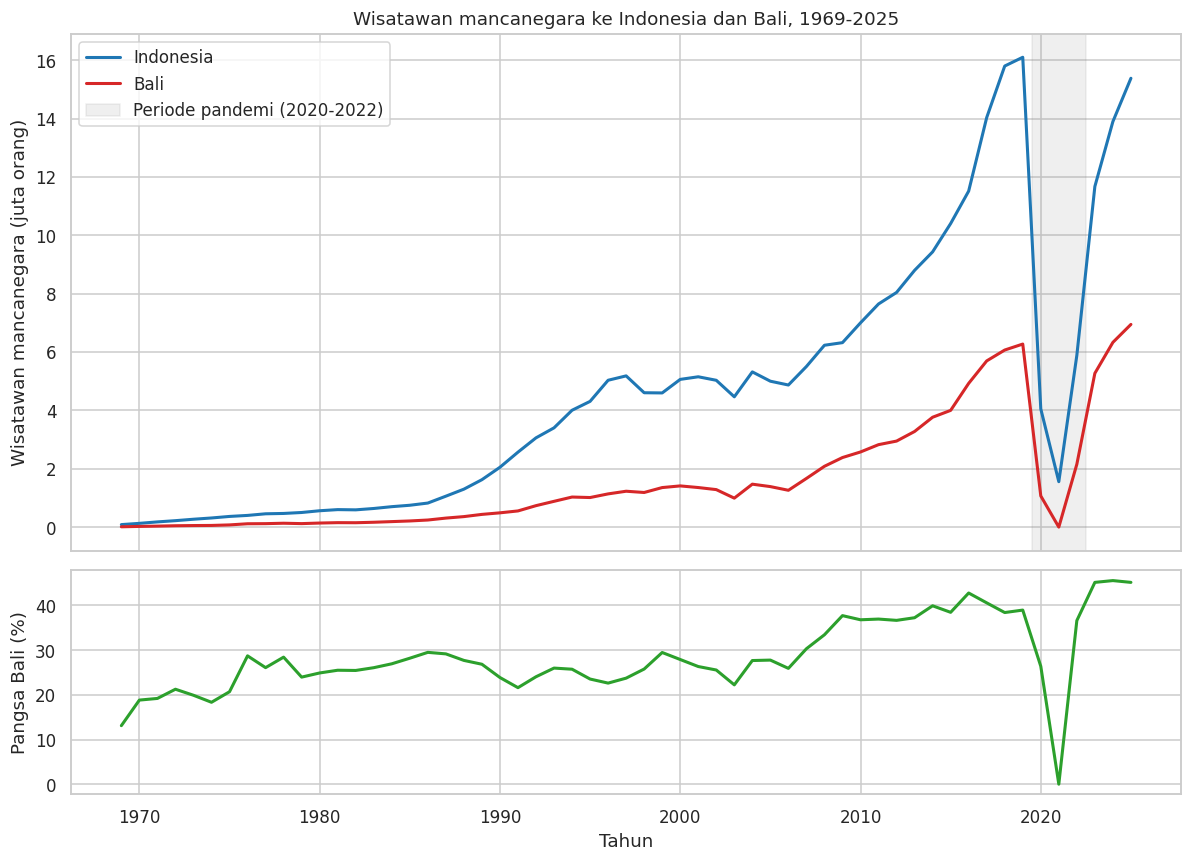

Penjelasan: wisman Bali tertinggi pada 2025 (6,948,754 orang). Pada 2019 = 6,275,210, 2020 = 1,069,473, 2025 = 6,948,754. Pangsa Bali terhadap Indonesia pada 2025 = 45.2%. Catatan: nilai Bali 2021 = 51 sangat ekstrem dan dipertahankan sesuai sumber.


In [29]:
# ===== 11.1 Tren wisman Bali dan Indonesia 1969-2025 =====
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax[0].plot(c_hist.tahun, c_hist.wisman_indonesia / 1e6, label="Indonesia", color="#1f77b4", lw=2)
ax[0].plot(c_hist.tahun, c_hist.wisman_bali / 1e6, label="Bali", color="#d62728", lw=2)
ax[0].axvspan(2019.5, 2022.5, color="grey", alpha=0.12, label="Periode pandemi (2020-2022)")
ax[0].set_ylabel("Wisatawan mancanegara (juta orang)")
ax[0].set_title("Wisatawan mancanegara ke Indonesia dan Bali, 1969-2025")
ax[0].legend()
ax[1].plot(c_hist.tahun, c_hist.pangsa_bali_pct, color="#2ca02c", lw=2)
ax[1].set_ylabel("Pangsa Bali (%)"); ax[1].set_xlabel("Tahun")
plt.tight_layout(); plt.show()

h = c_hist.set_index("tahun")
puncak = h.wisman_bali.idxmax()
print(f"Penjelasan: wisman Bali tertinggi pada {puncak} ({int(h.loc[puncak,'wisman_bali']):,} orang). "
      f"Pada 2019 = {int(h.loc[2019,'wisman_bali']):,}, 2020 = {int(h.loc[2020,'wisman_bali']):,}, 2025 = {int(h.loc[2025,'wisman_bali']):,}. "
      f"Pangsa Bali terhadap Indonesia pada 2025 = {h.loc[2025,'pangsa_bali_pct']:.1f}%. "
      f"Catatan: nilai Bali 2021 = {int(h.loc[2021,'wisman_bali'])} sangat ekstrem dan dipertahankan sesuai sumber.")

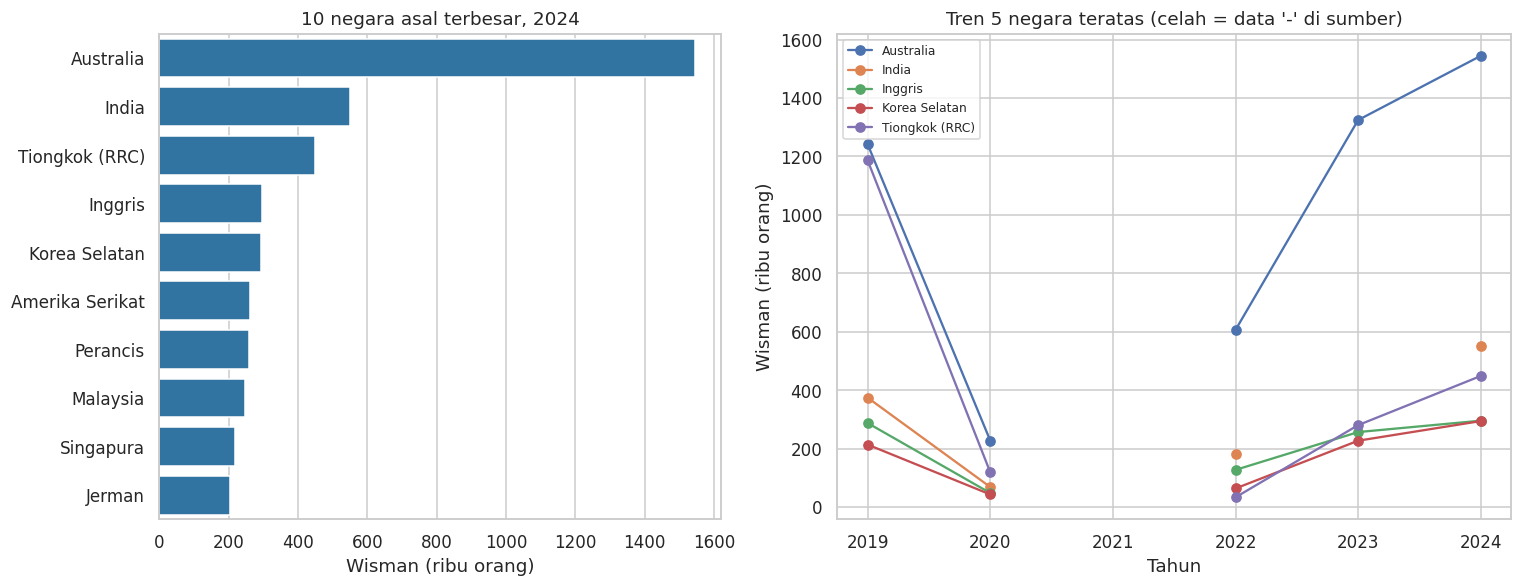

Penjelasan: pada 2024, negara asal terbesar adalah Australia (1,544,141 orang, 24.4% dari total 6,333,360). Tahun 2021 kosong untuk seluruh negara pada sumber; India 2023 juga bertanda '-' sehingga tidak diisi/ditebak.


In [30]:
# ===== 11.2 Wisman menurut negara asal =====
neg = c_negara[(c_negara.level == "negara") & (~c_negara.negara_std.str.contains("lainnya", case=False))].copy()
th_akhir = int(neg.dropna(subset=["jumlah_wisman"]).tahun.max())
top10 = neg[neg.tahun == th_akhir].nlargest(10, "jumlah_wisman")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.barplot(data=top10, y="negara_std", x=top10.jumlah_wisman / 1e3, color="#1f77b4", ax=ax[0])
ax[0].set_xlabel("Wisman (ribu orang)"); ax[0].set_ylabel(""); ax[0].set_title(f"10 negara asal terbesar, {th_akhir}")
top5 = top10.negara_std.head(5).tolist()
sub = neg[neg.negara_std.isin(top5)]
for n_, g in sub.groupby("negara_std"):
    g = g.sort_values("tahun")
    ax[1].plot(g.tahun, g.jumlah_wisman / 1e3, marker="o", label=n_)   # NaN (2021) tampil sebagai celah
ax[1].set_title("Tren 5 negara teratas (celah = data '-' di sumber)")
ax[1].set_xlabel("Tahun"); ax[1].set_ylabel("Wisman (ribu orang)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

tot_th = c_negara[(c_negara.level == "total") & (c_negara.tahun == th_akhir)].jumlah_wisman.iloc[0]
print(f"Penjelasan: pada {th_akhir}, negara asal terbesar adalah {top10.iloc[0].negara_std} ({int(top10.iloc[0].jumlah_wisman):,} orang, "
      f"{top10.iloc[0].jumlah_wisman / tot_th * 100:.1f}% dari total {int(tot_th):,}). Tahun 2021 kosong untuk seluruh negara pada sumber; "
      "India 2023 juga bertanda '-' sehingga tidak diisi/ditebak.")

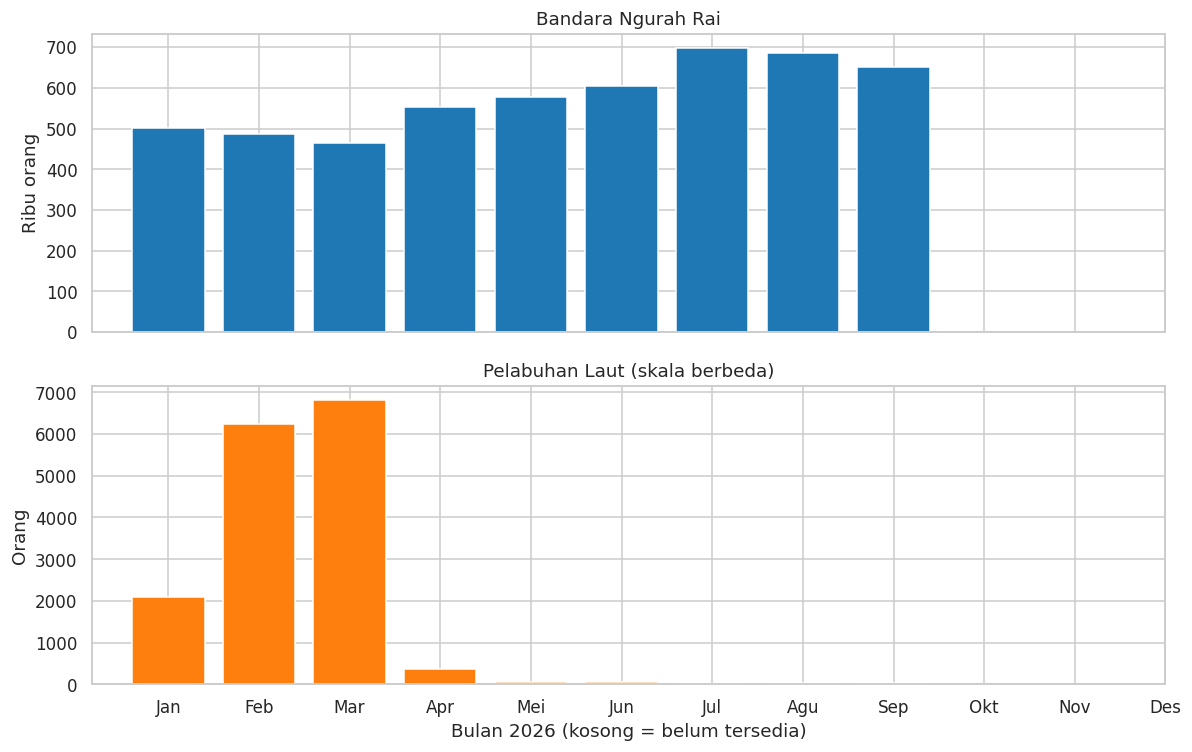

Penjelasan: pada bulan tersedia (9 bulan), Bandara Ngurah Rai menyumbang 99.70% kunjungan (5,221,450 dari 5,237,128). Bulan tertinggi: Juli (697,809). Pelabuhan ditampilkan pada sumbu terpisah karena skalanya jauh lebih kecil.


In [31]:
# ===== 11.3 Wisman menurut pintu masuk (bulanan, 2026) =====
pm = c_pintu[c_pintu.pintu_masuk != "Jumlah"]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
b = pm[pm.pintu_masuk == "Bandara Ngurah Rai"].sort_values("bulan_num")
p_ = pm[pm.pintu_masuk == "Pelabuhan Laut"].sort_values("bulan_num")
ax[0].bar(b.bulan_num, b.jumlah_wisman / 1e3, color="#1f77b4"); ax[0].set_ylabel("Ribu orang"); ax[0].set_title("Bandara Ngurah Rai")
ax[1].bar(p_.bulan_num, p_.jumlah_wisman, color="#ff7f0e"); ax[1].set_ylabel("Orang"); ax[1].set_title("Pelabuhan Laut (skala berbeda)")
ax[1].set_xticks(range(1, 13)); ax[1].set_xticklabels([NAMA_BULAN[i][:3] for i in range(1, 13)]); ax[1].set_xlabel("Bulan 2026 (kosong = belum tersedia)")
plt.tight_layout(); plt.show()

jum = c_pintu[c_pintu.pintu_masuk == "Jumlah"].dropna(subset=["jumlah_wisman"])
tot_b, tot_p = b.jumlah_wisman.sum(), p_.jumlah_wisman.sum()
print(f"Penjelasan: pada bulan tersedia ({len(jum)} bulan), Bandara Ngurah Rai menyumbang {tot_b / (tot_b + tot_p) * 100:.2f}% kunjungan "
      f"({int(tot_b):,} dari {int(tot_b + tot_p):,}). Bulan tertinggi: {NAMA_BULAN[int(jum.loc[jum.jumlah_wisman.idxmax(), 'bulan_num'])]} ({int(jum.jumlah_wisman.max()):,}). "
      "Pelabuhan ditampilkan pada sumbu terpisah karena skalanya jauh lebih kecil.")

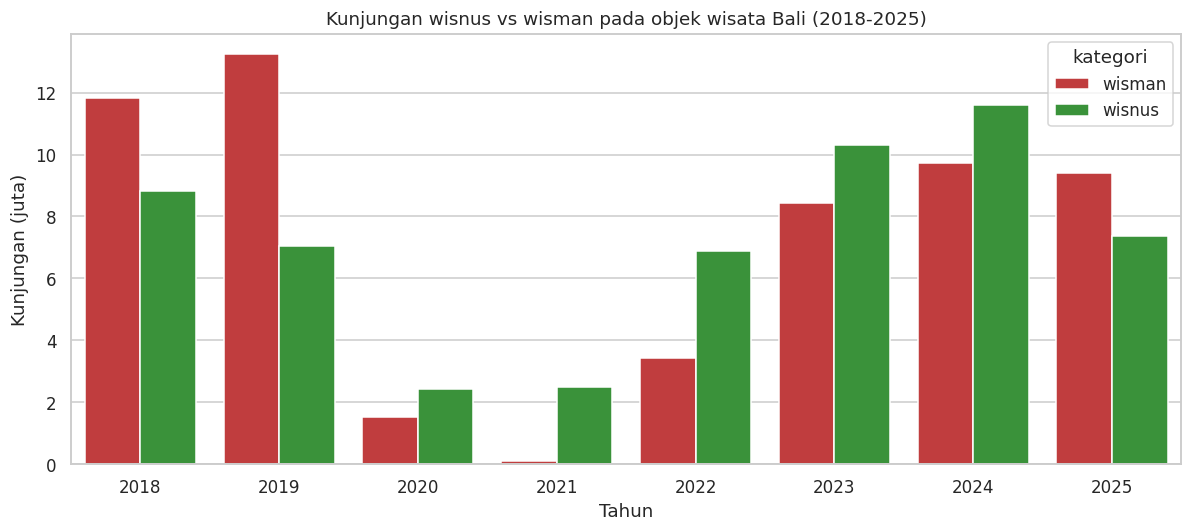

,wisman,wisnus,objek_ber_data
tahun,,,
2018,11825464.0,8836706.0,157
2019,13235139.0,7045775.0,148
2020,1529858.0,2423770.0,173
2021,100620.0,2493739.0,243
2022,3427920.0,6883351.0,236
2023,8420045.0,10312520.0,253
2024,9736523.0,11605188.0,237
2025,9399493.0,7358770.0,213


Penjelasan: jumlah di atas = penjumlahan seluruh objek yang punya nilai valid. Objek bernilai '-' tidak dihitung (bukan nol), sehingga jumlah objek yang berdata berbeda tiap tahun (kolom objek_ber_data) dan perubahan total antar tahun juga dipengaruhi cakupan pencatatan. Tahun 2016-2017 tidak ditampilkan karena sumber tidak memisahkan wisnus/wisman.


In [32]:
# ===== 11.4 Wisnus vs wisman pada objek wisata (total tahunan) =====
tk = c_objek[c_objek.kategori.isin(["wisnus", "wisman"])]
tahunan = tk.groupby(["tahun", "kategori"]).kunjungan.sum(min_count=1).reset_index()
n_objek = tk.dropna(subset=["kunjungan"]).groupby("tahun").objek.nunique().rename("objek_ber_data")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=tahunan, x="tahun", y=tahunan.kunjungan / 1e6, hue="kategori", palette={"wisnus": "#2ca02c", "wisman": "#d62728"}, ax=ax)
ax.set_ylabel("Kunjungan (juta)"); ax.set_xlabel("Tahun"); ax.set_title("Kunjungan wisnus vs wisman pada objek wisata Bali (2018-2025)")
plt.tight_layout(); plt.show()

display(tahunan.pivot(index="tahun", columns="kategori", values="kunjungan").join(n_objek).round(0))
print("Penjelasan: jumlah di atas = penjumlahan seluruh objek yang punya nilai valid. Objek bernilai '-' tidak dihitung (bukan nol), sehingga "
      "jumlah objek yang berdata berbeda tiap tahun (kolom objek_ber_data) dan perubahan total antar tahun juga dipengaruhi cakupan pencatatan. "
      "Tahun 2016-2017 tidak ditampilkan karena sumber tidak memisahkan wisnus/wisman.")

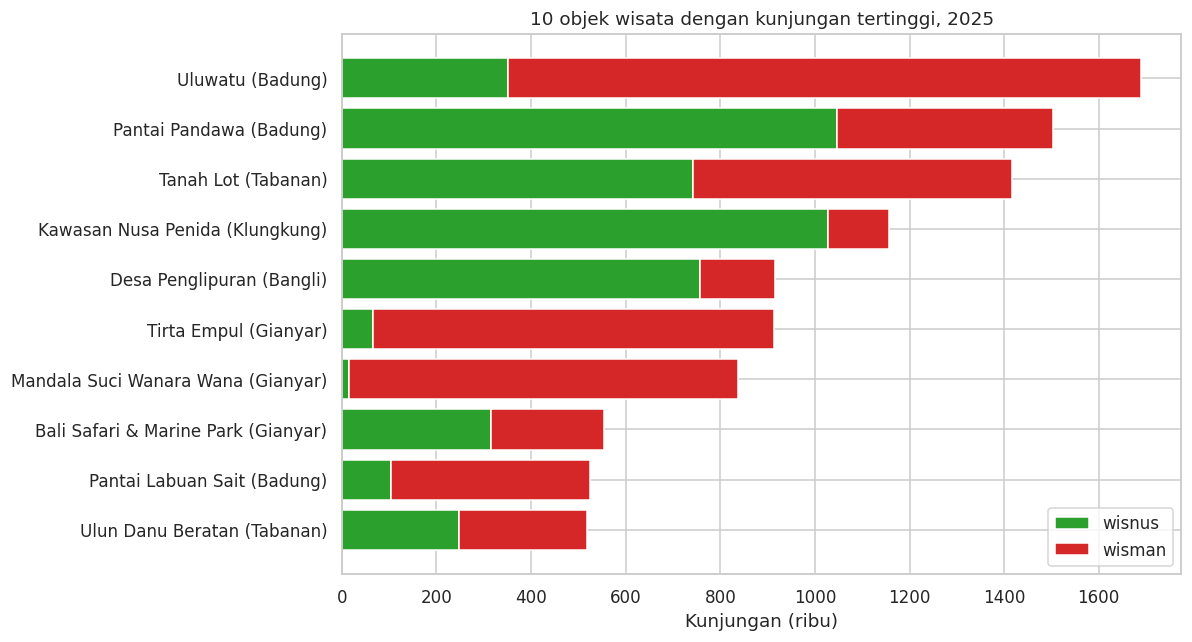

Penjelasan: objek tertinggi 2025 adalah Uluwatu (Badung) dengan 1,690,220 kunjungan (wisnus 351,790; wisman 1,338,430). Nilai '-' tidak dihitung sebagai nol.


In [33]:
# ===== 11.5 Sepuluh objek wisata dengan kunjungan tertinggi =====
th_obj = int(c_objek[c_objek.kategori.isin(["wisnus", "wisman"])].dropna(subset=["kunjungan"]).tahun.max())
pv = (c_objek[(c_objek.tahun == th_obj) & c_objek.kategori.isin(["wisnus", "wisman"])]
      .pivot_table(index=["kabupaten", "objek"], columns="kategori", values="kunjungan", aggfunc=lambda s: s.sum(min_count=1)))
pv["total"] = pv[["wisnus", "wisman"]].sum(axis=1, min_count=1)
top = pv.nlargest(10, "total").reset_index()
top["label"] = top.objek + " (" + top.kabupaten + ")"

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top.label[::-1], top.wisnus[::-1].fillna(0) / 1e3, label="wisnus", color="#2ca02c")
ax.barh(top.label[::-1], top.wisman[::-1].fillna(0) / 1e3, left=top.wisnus[::-1].fillna(0) / 1e3, label="wisman", color="#d62728")
ax.set_xlabel("Kunjungan (ribu)"); ax.set_title(f"10 objek wisata dengan kunjungan tertinggi, {th_obj}"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Penjelasan: objek tertinggi {th_obj} adalah {top.iloc[0].objek} ({top.iloc[0].kabupaten}) dengan {int(top.iloc[0].total):,} kunjungan "
      f"(wisnus {int(top.iloc[0].wisnus or 0):,}; wisman {int(top.iloc[0].wisman or 0):,}). Nilai '-' tidak dihitung sebagai nol.")

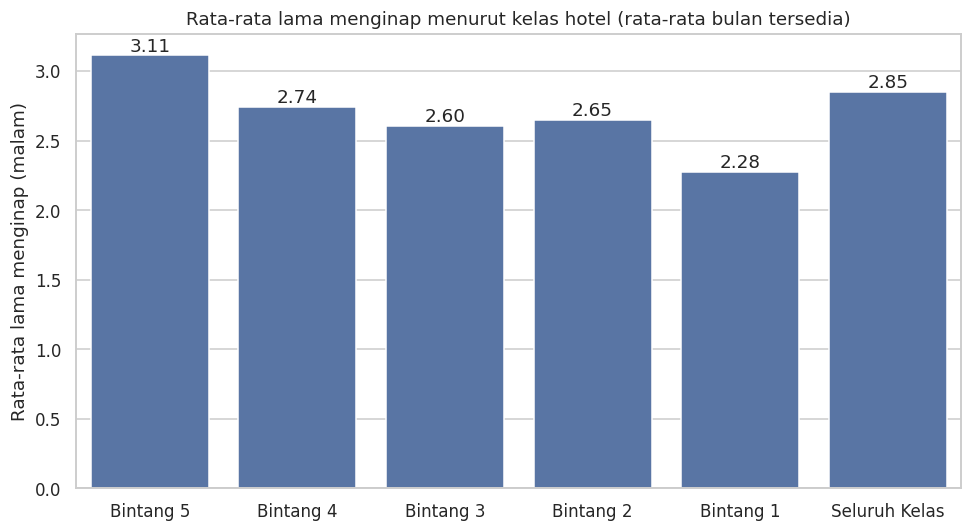

Penjelasan: kelas dengan rata-rata menginap terpanjang: Bintang 5 (3.11 malam); terpendek: Bintang 1 (2.28 malam). Data hanya 9 bulan 2026 dan tidak memisahkan tamu asing vs domestik.


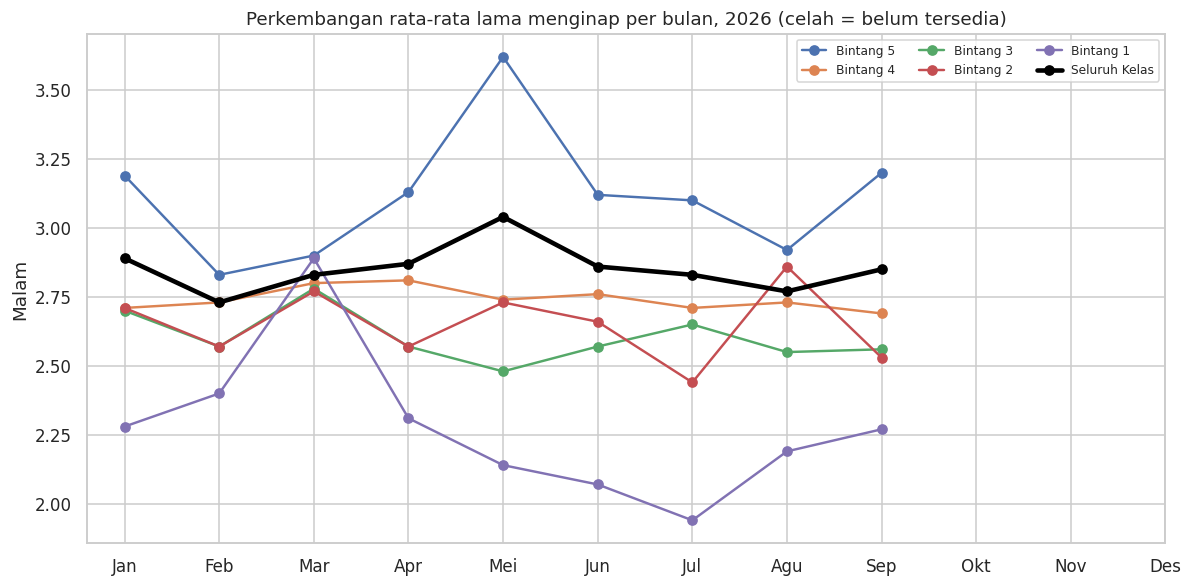

Penjelasan: untuk seluruh kelas, bulan terpanjang = Mei (3.04 malam), terpendek = Februari (2.73). Selisih antarbulan relatif kecil; dengan hanya satu tahun data, pola musiman belum dapat disimpulkan.


In [34]:
# ===== 11.6 & 11.7 Lama menginap: per kelas hotel dan per bulan =====
kelas_urut = ["Bintang 5", "Bintang 4", "Bintang 3", "Bintang 2", "Bintang 1", "Seluruh Kelas"]
rata = c_inap.groupby("kelas_hotel").rata_lama_menginap_malam.mean().reindex(kelas_urut).reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=rata, x="kelas_hotel", y="rata_lama_menginap_malam", color="#4c72b0", ax=ax)
ax.set_ylabel("Rata-rata lama menginap (malam)"); ax.set_xlabel(""); ax.set_title("Rata-rata lama menginap menurut kelas hotel (rata-rata bulan tersedia)")
for i, v in enumerate(rata.rata_lama_menginap_malam):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.show()
print(f"Penjelasan: kelas dengan rata-rata menginap terpanjang: {rata.loc[rata.rata_lama_menginap_malam[:5].idxmax(), 'kelas_hotel']} "
      f"({rata.rata_lama_menginap_malam[:5].max():.2f} malam); terpendek: {rata.loc[rata.rata_lama_menginap_malam[:5].idxmin(), 'kelas_hotel']} "
      f"({rata.rata_lama_menginap_malam[:5].min():.2f} malam). Data hanya {int(c_inap.rata_lama_menginap_malam.notna().sum() / 6)} bulan 2026 dan tidak memisahkan tamu asing vs domestik.")

fig, ax = plt.subplots(figsize=(11, 5.5))
for kelas in kelas_urut:
    g = c_inap[c_inap.kelas_hotel == kelas].sort_values("bulan_num")
    ax.plot(g.bulan_num, g.rata_lama_menginap_malam, marker="o", lw=3 if kelas == "Seluruh Kelas" else 1.6,
            color="black" if kelas == "Seluruh Kelas" else None, label=kelas)
ax.set_xticks(range(1, 13)); ax.set_xticklabels([NAMA_BULAN[i][:3] for i in range(1, 13)])
ax.set_ylabel("Malam"); ax.set_title("Perkembangan rata-rata lama menginap per bulan, 2026 (celah = belum tersedia)"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()
sk = c_inap[c_inap.kelas_hotel == "Seluruh Kelas"].dropna(subset=["rata_lama_menginap_malam"])
print(f"Penjelasan: untuk seluruh kelas, bulan terpanjang = {NAMA_BULAN[int(sk.loc[sk.rata_lama_menginap_malam.idxmax(), 'bulan_num'])]} "
      f"({sk.rata_lama_menginap_malam.max():.2f} malam), terpendek = {NAMA_BULAN[int(sk.loc[sk.rata_lama_menginap_malam.idxmin(), 'bulan_num'])]} ({sk.rata_lama_menginap_malam.min():.2f}). "
      "Selisih antarbulan relatif kecil; dengan hanya satu tahun data, pola musiman belum dapat disimpulkan.")

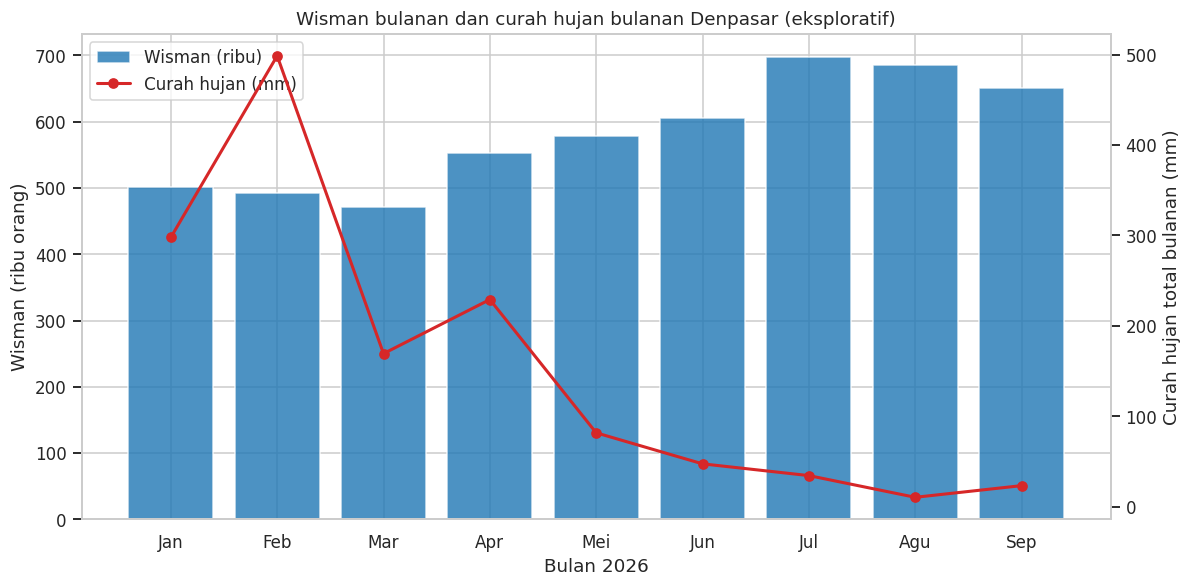

Penjelasan: n = 9 bulan. Korelasi Spearman wisman vs curah hujan = -0.85. Dengan n sekecil ini, satu titik cuaca (Denpasar), dan satu tahun data, angka ini hanya gambaran eksploratif. Korelasi tidak membuktikan bahwa hujan menyebabkan perubahan kunjungan (musim liburan, kalender, harga tiket, dsb. tidak dikendalikan).


/tmp/ipykernel_1268/2669774015.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  if (~ab.bulan_lengkap.fillna(True)).any():


In [35]:
# ===== 11.8 Curah hujan vs jumlah wisman bulanan =====
ab = hasil_B[(hasil_B.pintu_masuk == "Jumlah") & hasil_B.siap_analisis].sort_values("bulan_num")
if len(ab) < 2:
    print("Data gabungan cuaca-wisman belum cukup untuk digambar (API gagal atau belum ada bulan yang tumpang tindih).")
else:
    fig, ax1 = plt.subplots(figsize=(11, 5.5))
    ax1.bar(ab.bulan_num, ab.jumlah_wisman / 1e3, color="#1f77b4", alpha=0.8, label="Wisman (ribu)")
    ax1.set_ylabel("Wisman (ribu orang)"); ax1.set_xlabel("Bulan 2026")
    ax1.set_xticks(ab.bulan_num); ax1.set_xticklabels([NAMA_BULAN[int(m)][:3] for m in ab.bulan_num])
    ax2 = ax1.twinx()
    ax2.plot(ab.bulan_num, ab.curah_hujan_total_mm, color="#d62728", marker="o", lw=2, label="Curah hujan (mm)")
    ax2.set_ylabel("Curah hujan total bulanan (mm)"); ax2.grid(False)
    ax1.set_title("Wisman bulanan dan curah hujan bulanan Denpasar (eksploratif)")
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, loc="upper left")
    plt.tight_layout(); plt.show()

    rho = ab[["jumlah_wisman", "curah_hujan_total_mm"]].corr(method="spearman").iloc[0, 1]
    print(f"Penjelasan: n = {len(ab)} bulan. Korelasi Spearman wisman vs curah hujan = {rho:.2f}. "
          "Dengan n sekecil ini, satu titik cuaca (Denpasar), dan satu tahun data, angka ini hanya gambaran eksploratif. "
          "Korelasi tidak membuktikan bahwa hujan menyebabkan perubahan kunjungan (musim liburan, kalender, harga tiket, dsb. tidak dikendalikan).")
    if (~ab.bulan_lengkap.fillna(True)).any():
        print("Peringatan: ada bulan cuaca yang belum lengkap pada data gabungan.")

## BAGIAN 12 — Provenance, metadata, dan penyimpanan hasil

`provenance.csv` mencatat setiap sumber dan setiap file yang disimpan: nama sumber, URL, tanggal akses, lisensi/ketentuan, jenis akuisisi, nama file, hash MD5, dan keterangan. Checklist etika diperbarui dengan hasil robots.txt dan provenance.

In [36]:
# ===== 12.1 Perbarui checklist etika dengan hasil akhir =====
state = {}
if robots["status"] is None:
    state["etika5_status"] = "Belum terverifikasi"
    state["etika5_bukti"] = f"robots.txt tidak dapat diambil ({robots['robots_url']}): {robots['alasan']}"
else:
    state["etika5_status"] = "Sebagian (robots.txt diperiksa; syarat penggunaan belum diverifikasi)" if robots["boleh"] else "Scraping tidak dilakukan (dilarang/tidak jelas)"
    state["etika5_bukti"] = f"robots.txt {robots['robots_url']} (HTTP {robots['status']}); hasil: {robots['alasan']}; file: {os.path.basename(FILE_ROBOTS) if robots['teks'] else '-'}"
state["etika5_jelas"] = "Ketentuan penggunaan portal belum dibaca otomatis; verifikasi manual diperlukan. Data dipakai non-komersial dan sumber disebutkan."
state["etika6_status"] = "Terpenuhi" if all(not v.startswith(BELUM) for k, v in URL_SUMBER.items()) else "Sebagian"
state["etika6_bukti"] = "provenance.csv (nama sumber, URL, tanggal akses, lisensi, MD5)"
state["etika6_jelas"] = "URL setiap dataset unggahan: " + ("lengkap." if state["etika6_status"] == "Terpenuhi" else "belum semuanya diisi pada kamus URL_SUMBER; isi untuk transparansi penuh.")
state["etika8_bukti"] = (f"Cakupan waktu: D1 {periode(c_hist.tahun)}; D2/D4 2026 (bulan terisi sampai {int(c_pintu.dropna(subset=['jumlah_wisman']).bulan_num.max())}); "
                         f"D3 {periode(c_negara.tahun)} (2021 kosong); D5 {periode(c_objek.tahun)}; cuaca {len(weather_daily)} hari di satu titik (Denpasar).")
df_etika = bangun_etika(state)
df_etika.to_csv(FILE_ETIKA, index=False)
display(df_etika[["no", "aspek_etika", "status"]])
STATUS["Data ethics checklist (final)"] = "berhasil"

,no,aspek_etika,status
0,1,Legalitas dan lisensi,Belum terverifikasi
1,2,Tujuan pengumpulan data,Terpenuhi
2,3,Privasi dan PII,Terpenuhi
3,4,Quasi-identifier,Terpenuhi (risiko rendah)
4,5,Persetujuan dan hak penggunaan,Sebagian (robots.txt diperiksa; syarat penggun...
5,6,Transparansi sumber,Sebagian
6,7,Keamanan data,Terpenuhi
7,8,Potensi bias,Terpenuhi (diidentifikasi)
8,9,Risiko penyalahgunaan,Terpenuhi (diidentifikasi)


In [37]:
# ===== 12.2 Metadata JSON =====
def ringkas_df(d):
    return {"baris": int(len(d)), "kolom": int(d.shape[1]), "sel_nan": int(d.isna().sum().sum())}

metadata = {
    "projek": "Bali Tourism Data Integration & Analytics",
    "mahasiswa": {"nama": NAMA_MAHASISWA, "nim": NIM},
    "dibuat_pada": dt.datetime.now().isoformat(timespec="seconds"),
    "lingkungan": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "colab": IN_COLAB},
    "user_agent": USER_AGENT,
    "api": {"endpoint": API_URL, "lokasi": {"lat": LAT, "lon": LON, "nama": "Denpasar, Bali"}, "variabel": VAR_HARIAN,
            "periode_diminta": [TGL_MULAI, TGL_AKHIR], "jumlah_baris": int(len(weather_daily))},
    "scraping": {"url": URL_TARGET, "robots_boleh": bool(robots["boleh"]), "robots_alasan": robots["alasan"], "jumlah_destinasi": int(len(df_scraped))},
    "tabel": {"wisatawan_historis": ringkas_df(c_hist), "pintu_masuk": ringkas_df(c_pintu), "kebangsaan": ringkas_df(c_negara),
              "lama_menginap": ringkas_df(c_inap), "objek_wisata": ringkas_df(c_objek), "weather_daily": ringkas_df(weather_daily),
              "weather_monthly": ringkas_df(weather_monthly), "destinasi_scraped": ringkas_df(df_scraped)},
    "integrasi": {"A_objek_wisata_scraping": {"kunci": "kunci_gabung (nama objek ternormalisasi)", "validate": "many_to_one", **val_A,
                                              "objek_unik": int(len(objek_unik)), "objek_cocok": int(cocok.sum())},
                  "B_pintu_masuk_cuaca": {"kunci": ["tahun", "bulan_num"], "validate": "many_to_one", **val_B}},
    "asumsi_dan_keterbatasan": [
        "Nilai '-' pada sumber diperlakukan sebagai NaN (bukan nol).",
        "Kolom 2016-2017 pada D5 tidak dipisah wisnus/wisman; diberi kategori 'total_gabungan' (diasumsikan jumlah keduanya).",
        "D4 tidak memisahkan tamu asing dan domestik.",
        "Kategori destinasi hasil scraping diturunkan dari kata kunci (inferensi), bukan dari situs.",
        "Cuaca hanya satu titik (Denpasar); analisis cuaca-kunjungan eksploratif, bukan kausal.",
        "Lisensi sumber yang belum diisi tercatat 'Belum terverifikasi'."],
    "status_proses": STATUS,
}
with open(os.path.join(DIR_FINAL, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)
print("metadata.json disimpan di", DIR_FINAL)

metadata.json disimpan di /content/drive/MyDrive/Bali_Tourism_Data_Project/data/final


In [38]:
# ===== 12.3 Provenance seluruh sumber dan file tersimpan =====
def baris_prov(nama_sumber, kunci, path, jenis, ket):
    ada = bool(path) and os.path.exists(path)
    return {"nama_sumber": nama_sumber, "url": URL_SUMBER.get(kunci, "-") if kunci else "-", "tanggal_akses": hari_ini(),
            "lisensi_atau_ketentuan": LISENSI.get(kunci, "Mengikuti sumber") if kunci else "Mengikuti sumber",
            "jenis_akuisisi": jenis, "nama_file": os.path.relpath(path, ROOT) if path else "-",
            "md5": md5_file(path) if ada else "file tidak tersimpan", "keterangan": ket}

prov = []
ket_d = {"D1_historis": "Wisman ke Indonesia & Bali 1969-2025", "D2_pintu": "Wisman bulanan menurut pintu masuk 2026",
         "D3_kebangsaan": "Wisman menurut kebangsaan 2019-2024", "D4_menginap": "Rata-rata lama menginap hotel bintang 2026",
         "D5_objek": "Kunjungan objek & daya tarik wisata 2016-2025 (Table 17)"}
for k, p in RAW_PATH.items():
    prov.append(baris_prov(f"{k} - penerbit: {PENERBIT[k]}", k, p, "Open dataset (CSV)" if p.endswith(".csv") else "Open dataset (Excel)", ket_d[k]))
prov.append(baris_prov("Open-Meteo Historical Weather API", "API_openmeteo", FILE_API_RAW, "API (JSON)", f"Respons mentah; status: {STATUS.get('API Open-Meteo')}"))
prov.append(baris_prov("Indonesia.Travel robots.txt", "SCRAPING", FILE_ROBOTS if robots["teks"] else None, "Web (robots.txt)", robots["alasan"]))
prov.append(baris_prov("Indonesia.Travel halaman destinasi Bali", "SCRAPING", FILE_HTML_RAW, "Web scraping (HTML mentah)", f"Status: {STATUS.get('Web scraping')}"))
if os.path.exists(FILE_DETAIL_RAW):
    prov.append(baris_prov("Indonesia.Travel halaman detail destinasi", "SCRAPING", FILE_DETAIL_RAW, "Web scraping (HTML detail)", "HTML detail (JSON url->html)"))
for folder, label in ((DIR_PROC, "processed"), (DIR_FINAL, "final")):
    for f in sorted(os.listdir(folder)):
        prov.append(baris_prov(f"Turunan (data/{label})", None, os.path.join(folder, f), "Hasil olahan notebook", "Dibuat dari sumber di atas oleh notebook ini"))

df_prov = pd.DataFrame(prov)
df_prov.to_csv(FILE_PROVENANCE, index=False)
print("provenance.csv:", len(df_prov), "baris")
display(df_prov[["nama_sumber", "jenis_akuisisi", "nama_file", "md5"]])

# Bukti data/raw tidak berubah: hitung ulang MD5 dan bandingkan dengan Bagian 2
cek_raw = all(md5_file(RAW_PATH[k]) == df_file.set_index("kode").loc[k, "md5"] for k in RAW_PATH)
print("\nSeluruh file dataset di data/raw identik dengan saat disalin (MD5 sama):", cek_raw)
assert cek_raw
STATUS["Provenance & metadata"] = "berhasil"

provenance.csv: 21 baris


,nama_sumber,jenis_akuisisi,nama_file,md5
0,D1_historis - penerbit: BPS Provinsi Bali (ter...,Open dataset (CSV),data/raw/Banyaknya Wisatawan Mancanegara ke Ba...,ab034ea9e86e16ae85766ee2b37f2af3
1,D2_pintu - penerbit: Belum terverifikasi (file...,Open dataset (CSV),data/raw/Jumlah Wisatawan Mancanegara Bulanan ...,2aef9e8b657603ba358b9d8bfb120410
2,D4_menginap - penerbit: Belum terverifikasi (f...,Open dataset (CSV),data/raw/Rata-Rata Lama Menginap Tamu Asing da...,18a8dabfca1d1058afbf370999a97aa9
3,D5_objek - penerbit: Dinas Pariwisata Provinsi...,Open dataset (Excel),data/raw/Table-17-Final-7.xlsx,ce9d625286e52fd80a8c58558a08e1e2
4,D3_kebangsaan - penerbit: BPS Provinsi Bali (t...,Open dataset (CSV),data/raw/_Banyaknya Wisatawan Mancanegara yang...,de3d83169c1492b8b035c264e6a0a148
5,Open-Meteo Historical Weather API,API (JSON),data/raw/open_meteo_raw.json,1a4a74d6b00885224dad13500464f701
6,Indonesia.Travel robots.txt,Web (robots.txt),data/raw/robots_indonesia_travel.txt,4970f5eb979fbe115615febd16cc2a2f
7,Indonesia.Travel halaman destinasi Bali,Web scraping (HTML mentah),data/raw/tourism_scraping_raw.html,ad85464f65435e51e7c97c3dd4eb0697
8,Turunan (data/processed),Hasil olahan notebook,data/processed/destinasi_scraped.csv,408f03909af98a91d4920a05d4b801fd
9,Turunan (data/processed),Hasil olahan notebook,data/processed/lama_menginap_clean.csv,4c1207caa3a440f36522d2cf9bfc0866



Seluruh file dataset di data/raw identik dengan saat disalin (MD5 sama): True


## BAGIAN 13 — Kesimpulan dan daftar file

In [39]:
# ===== 13.1 Kesimpulan (angka dihitung dari hasil aktual) =====
h = c_hist.set_index("tahun")
ukuran_total = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ROOT) for f in fs) / 1024 ** 2
n_valid_obj = int(c_objek.kunjungan.notna().sum())

teks = f"""
### Ringkasan hasil
- **Dataset diakuisisi:** 5 dari 5 (4 CSV + 1 Excel) tersimpan tanpa perubahan di `data/raw` (MD5 dicatat dan diverifikasi ulang).
- **API:** Open-Meteo -> {STATUS.get('API Open-Meteo')}; {len(weather_daily)} baris harian ({'memenuhi' if len(weather_daily) >= 30 else 'BELUM memenuhi'} syarat >= 30 baris).
- **Web scraping:** {STATUS.get('Web scraping')}; {len(df_scraped)} destinasi tersimpan.
- **Cleaning:** nilai '-' dipertahankan sebagai NaN; D5 menghasilkan {n_valid_obj:,} observasi valid dari {len(c_objek):,} baris long ({c_objek[['kabupaten','objek']].drop_duplicates().shape[0]} objek) -> {'memenuhi' if n_valid_obj >= 100 else 'BELUM memenuhi'} syarat >= 100.
- **Integrasi A:** {STATUS.get('Integrasi A (objek wisata + scraping)')}. **Integrasi B:** {STATUS.get('Integrasi B (pintu masuk + cuaca)')}.
- **Validasi:** jumlah baris sebelum = sesudah merge (assert lolos), kunci kanan unik, `validate='many_to_one'` lolos.

### Temuan utama (eksploratif)
- Wisman Bali: {int(h.loc[2019,'wisman_bali']):,} (2019) -> {int(h.loc[2020,'wisman_bali']):,} (2020) -> {int(h.loc[2025,'wisman_bali']):,} (2025); pangsa Bali terhadap Indonesia 2025 = {h.loc[2025,'pangsa_bali_pct']:.1f}%.
- Negara asal terbesar {th_akhir}: {top10.iloc[0].negara_std} ({int(top10.iloc[0].jumlah_wisman):,}).
- Objek wisata dengan kunjungan tertinggi {th_obj}: {top.iloc[0].objek} ({int(top.iloc[0].total):,}).
- Rata-rata lama menginap seluruh kelas hotel berkisar {sk.rata_lama_menginap_malam.min():.2f}-{sk.rata_lama_menginap_malam.max():.2f} malam pada bulan yang tersedia (2026).

### Keterbatasan
- D2 dan D4 hanya memuat Januari-September 2026; bulan lain `-` (bukan nol).
- D3: tahun 2021 kosong untuk semua negara; India 2023 kosong.
- D5: 2016-2017 tidak dipisah wisnus/wisman; objek berbeda-beda cakupannya per tahun.
- D4 tidak memisahkan tamu asing dan domestik.
- Cuaca satu titik (Denpasar); hubungan cuaca-kunjungan hanya eksploratif (n kecil), bukan sebab-akibat.
- Lisensi yang belum diisi tercatat "Belum terverifikasi"; kategori destinasi hasil scraping adalah inferensi kata kunci.
"""
display(Markdown(teks))


### Ringkasan hasil
- **Dataset diakuisisi:** 5 dari 5 (4 CSV + 1 Excel) tersimpan tanpa perubahan di `data/raw` (MD5 dicatat dan diverifikasi ulang).
- **API:** Open-Meteo -> berhasil; 316 baris harian (memenuhi syarat >= 30 baris).
- **Web scraping:** berhasil (33 destinasi); 33 destinasi tersimpan.
- **Cleaning:** nilai '-' dipertahankan sebagai NaN; D5 menghasilkan 3,531 observasi valid dari 5,220 baris long (290 objek) -> memenuhi syarat >= 100.
- **Integrasi A:** berhasil; objek cocok 0/289. **Integrasi B:** berhasil.
- **Validasi:** jumlah baris sebelum = sesudah merge (assert lolos), kunci kanan unik, `validate='many_to_one'` lolos.

### Temuan utama (eksploratif)
- Wisman Bali: 6,275,210 (2019) -> 1,069,473 (2020) -> 6,948,754 (2025); pangsa Bali terhadap Indonesia 2025 = 45.2%.
- Negara asal terbesar 2024: Australia (1,544,141).
- Objek wisata dengan kunjungan tertinggi 2025: Uluwatu (1,690,220).
- Rata-rata lama menginap seluruh kelas hotel berkisar 2.73-3.04 malam pada bulan yang tersedia (2026).

### Keterbatasan
- D2 dan D4 hanya memuat Januari-September 2026; bulan lain `-` (bukan nol).
- D3: tahun 2021 kosong untuk semua negara; India 2023 kosong.
- D5: 2016-2017 tidak dipisah wisnus/wisman; objek berbeda-beda cakupannya per tahun.
- D4 tidak memisahkan tamu asing dan domestik.
- Cuaca satu titik (Denpasar); hubungan cuaca-kunjungan hanya eksploratif (n kecil), bukan sebab-akibat.
- Lisensi yang belum diisi tercatat "Belum terverifikasi"; kategori destinasi hasil scraping adalah inferensi kata kunci.


In [40]:
# ===== 13.2 Status proses dan daftar file akhir =====
print("STATUS PROSES")
for k, v in STATUS.items():
    print(f" - {k}: {v}")

print("\nDAFTAR FILE HASIL (relatif terhadap folder projek):")
daftar = []
for r, _, fs in os.walk(ROOT):
    for f in sorted(fs):
        p = os.path.join(r, f)
        daftar.append({"file": os.path.relpath(p, ROOT), "ukuran_KB": round(os.path.getsize(p) / 1024, 2)})
display(pd.DataFrame(daftar).sort_values("file").reset_index(drop=True))
print(f"\nTotal ukuran folder projek: {ukuran_total:.3f} MB")
print("Untuk dikumpulkan: notebook ini (sudah dijalankan), folder data/raw, data/processed, data/final, "
      "data_ethics_checklist.csv, provenance.csv, metadata, serta tautan Colab/GitHub.")

STATUS PROSES
 - Penyimpanan raw (5 dataset + MD5): berhasil
 - Identifikasi 5 dataset: berhasil
 - Estimasi storage: berhasil
 - Data ethics checklist (awal): berhasil
 - API Open-Meteo: berhasil
 - Web scraping: berhasil (33 destinasi)
 - Cleaning & normalisasi (5 dataset): berhasil
 - Integrasi A (objek wisata + scraping): berhasil; objek cocok 0/289
 - Integrasi B (pintu masuk + cuaca): berhasil
 - Validasi merge (A & B): berhasil (assert lolos)
 - Data ethics checklist (final): berhasil
 - Provenance & metadata: berhasil

DAFTAR FILE HASIL (relatif terhadap folder projek):


,file,ukuran_KB
0,data/final/fuzzy_candidates_for_review.csv,0.05
1,data/final/integrated_monthly_weather.csv,5.38
2,data/final/integrated_tourism.csv,650.34
3,data/final/metadata.json,3.52
4,data/final/objek_tidak_cocok.csv,10.28
5,data/processed/destinasi_scraped.csv,8.94
6,data/processed/lama_menginap_clean.csv,3.13
7,data/processed/objek_wisata_clean.csv,481.34
8,data/processed/weather_daily.csv,15.77
9,data/processed/weather_monthly.csv,1.17



Total ukuran folder projek: 1.407 MB
Untuk dikumpulkan: notebook ini (sudah dijalankan), folder data/raw, data/processed, data/final, data_ethics_checklist.csv, provenance.csv, metadata, serta tautan Colab/GitHub.
